In [ ]:
!pip install scanpy scikit-misc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 5.1 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take 

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
%matplotlib inline

## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [ ]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  29.8M      0 --:--:-- --:--:-- --:--:-- 29.9M


In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [ ]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [ ]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [ ]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [ ]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [ ]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [ ]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [ ]:
print(adata.obs.columns.tolist())
print(adata.var.columns.tolist())
adata.obs.head()

['n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt']
['gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts']


,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,total_counts_mt,log1p_total_counts_mt,pct_counts_mt
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,73.0,4.304065,3.015283
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,186.0,5.231109,3.793596
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,28.0,3.367296,0.889171
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,46.0,3.850148,1.743085
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,12.0,2.564949,1.223242


In [ ]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

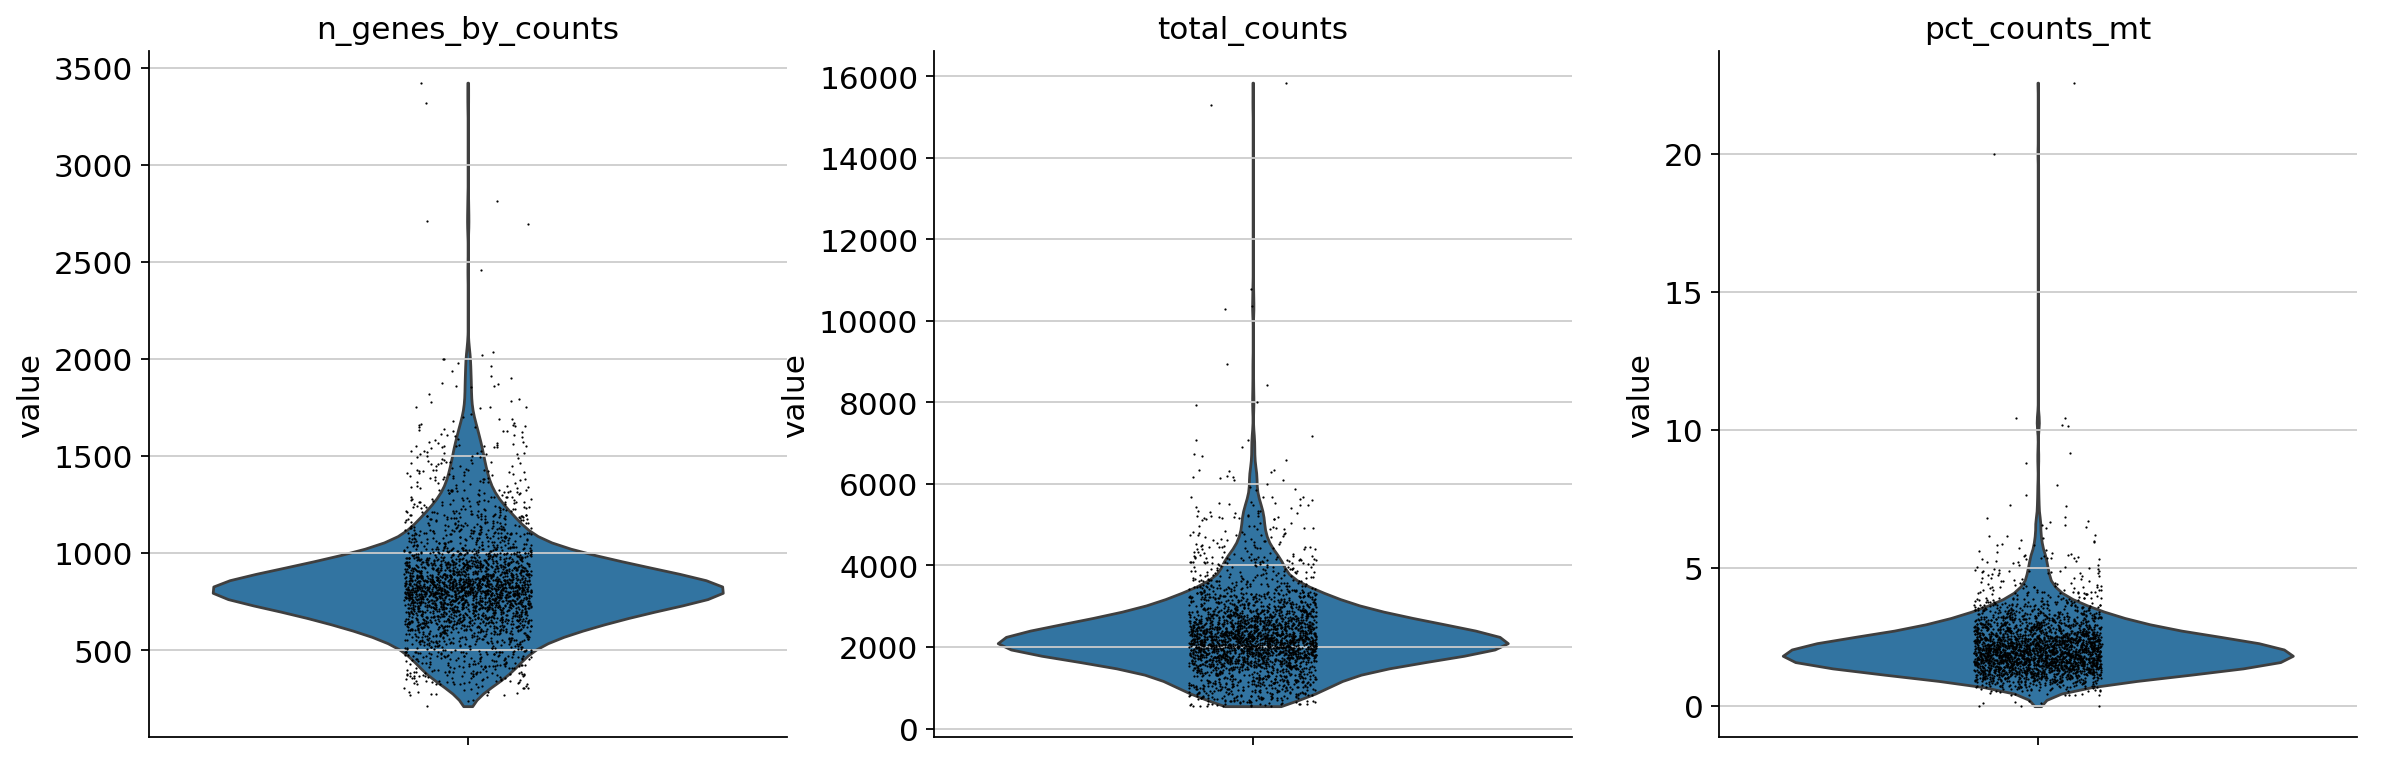

In [ ]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [ ]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [ ]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

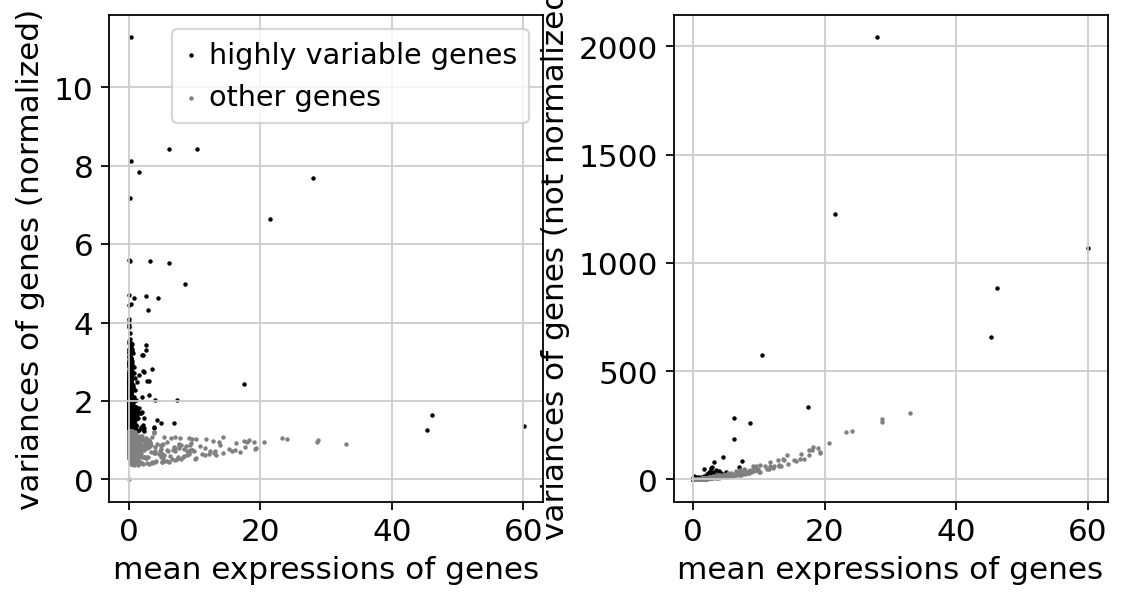

In [ ]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

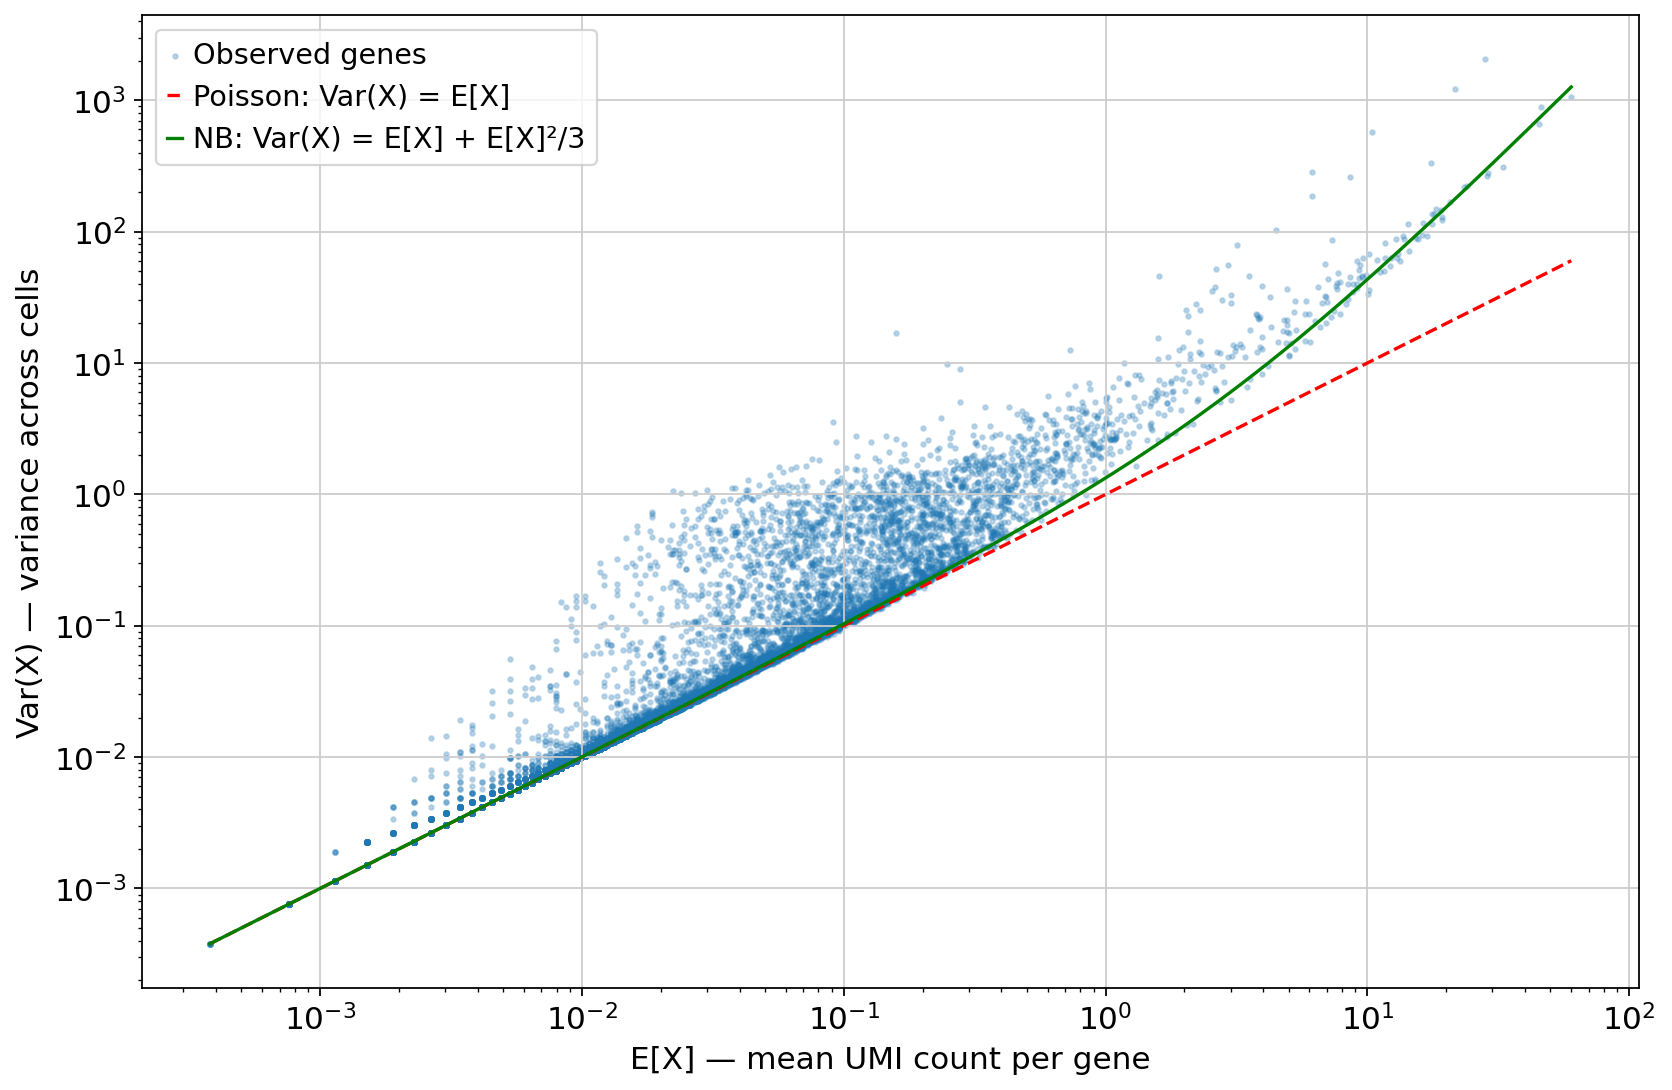

In [ ]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

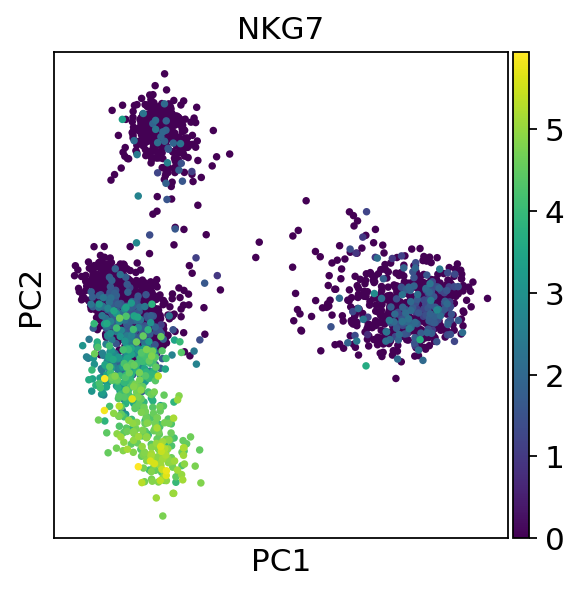

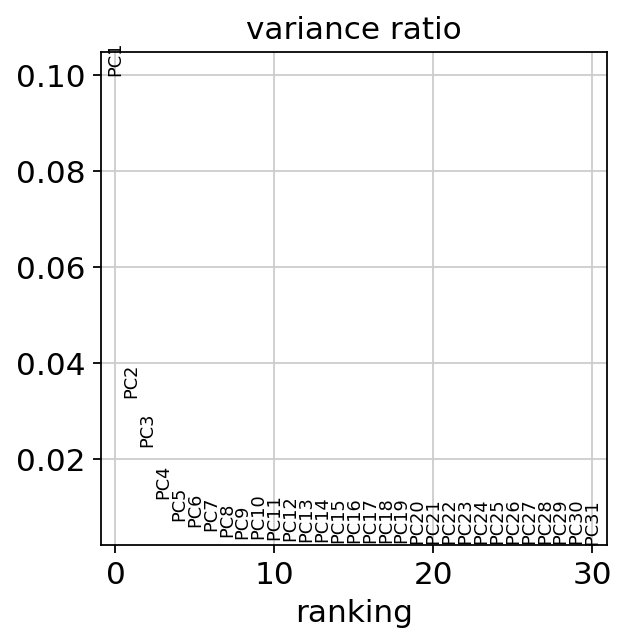

In [ ]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

1. В adata.layers после наших шагов: counts - копия исходной матрицы UMI counts (до нормализации).
   После normalize_total+log1p в X лежит log-нормализованная матрица, а layers["counts"] - сырые counts.
2. QC можно делать по: рибосомным генам (RPS*, RPL*), генам гемоглобина (HBA*, HBB* ), генам теплового шока (HSP*), половым хромосомам (XIST, RPS4Y1), генам апоптоза/стресса.
3. Лучше по gtf/gff: он даёт хромосому, биотип, координаты — можно корректно выделить MT/рибосомные гены без хрупкого поиска по префиксу имени.
4. У человека 13 белок-кодирующих MT-генов + 2 rRNA + tRNA; в 10x-матрице (hg19) обычно 13 генов MT-*.
   Не все митохондриальные транскрипты начинаются с MT- (rRNA/tRNA в матрицу не попадают).
5. Корова - MT-, собака - MT-, приматы MT-

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [ ]:
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"]   = adata.var_names.str.match(r"^HB[ABDEGQZ]\d*$")
adata.var["hsp"]  = adata.var_names.str.startswith("HSP")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt", "ribo", "hb", "hsp"],
    percent_top=None,
    inplace=True,
)
adata.obs[["total_counts", "n_genes_by_counts",
           "pct_counts_mt", "pct_counts_ribo",
           "pct_counts_hb", "pct_counts_hsp"]].describe()

,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,pct_counts_hsp
count,2638.000000,2638.000000,2638.000000,2638.000000,2638.000000,2638.000000
mean,1719.359375,848.647460,1.450953,16.067614,0.001504,0.346885
std,277.295532,262.760302,0.365931,3.382614,0.016432,0.176823
min,700.994263,212.000000,0.000000,2.258598,0.000000,0.000000
25%,1562.508026,699.000000,1.208648,13.727237,0.000000,0.226181
50%,1707.563477,819.000000,1.424893,16.295452,0.000000,0.341270
75%,1866.703217,954.000000,1.657075,18.193434,0.000000,0.463308
max,2910.010498,2413.000000,3.760242,36.457760,0.335922,1.002504


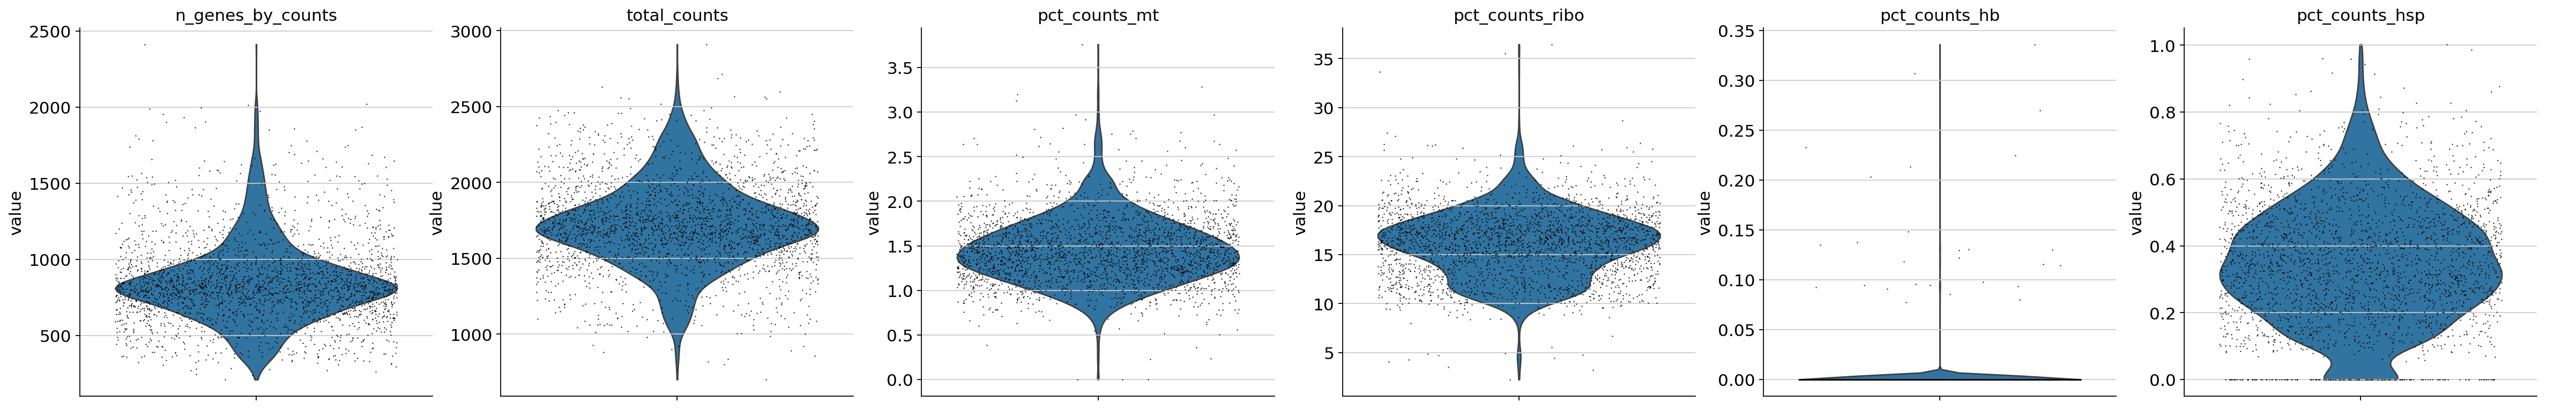

In [ ]:
qc_metrics = ["n_genes_by_counts", "total_counts",
              "pct_counts_mt", "pct_counts_ribo",
              "pct_counts_hb", "pct_counts_hsp"]
sc.pl.violin(adata, qc_metrics, multi_panel=True, jitter=0.4, rotation=45)

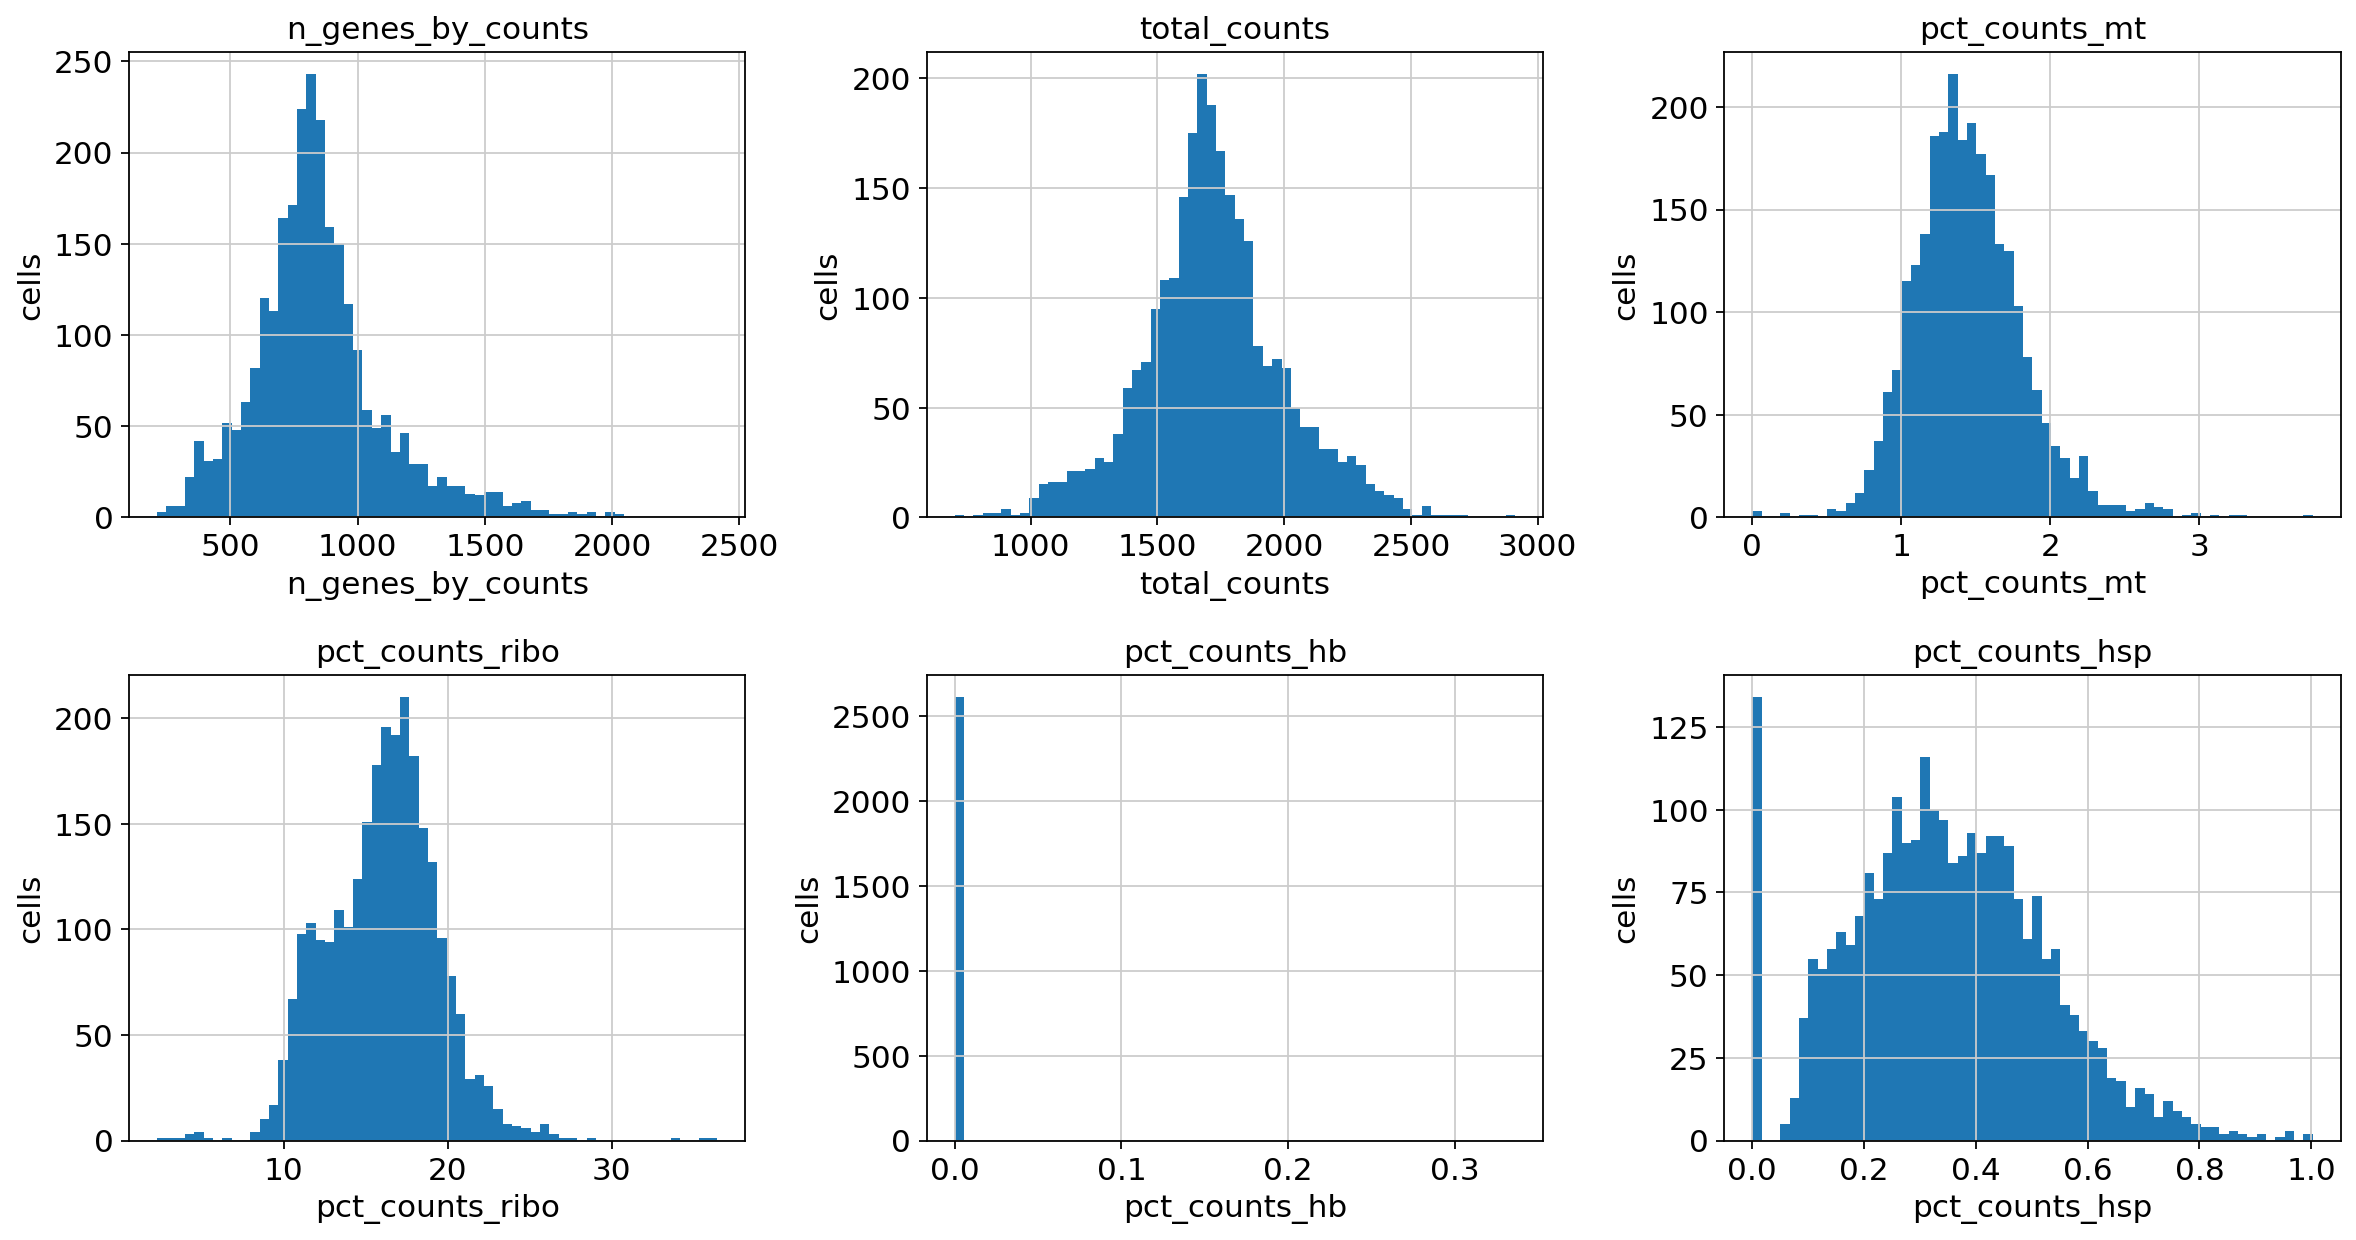

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, m in zip(axes.ravel(), qc_metrics):
    ax.hist(adata.obs[m], bins=60)
    ax.set_title(m); ax.set_xlabel(m); ax.set_ylabel("cells")
plt.tight_layout(); plt.show()

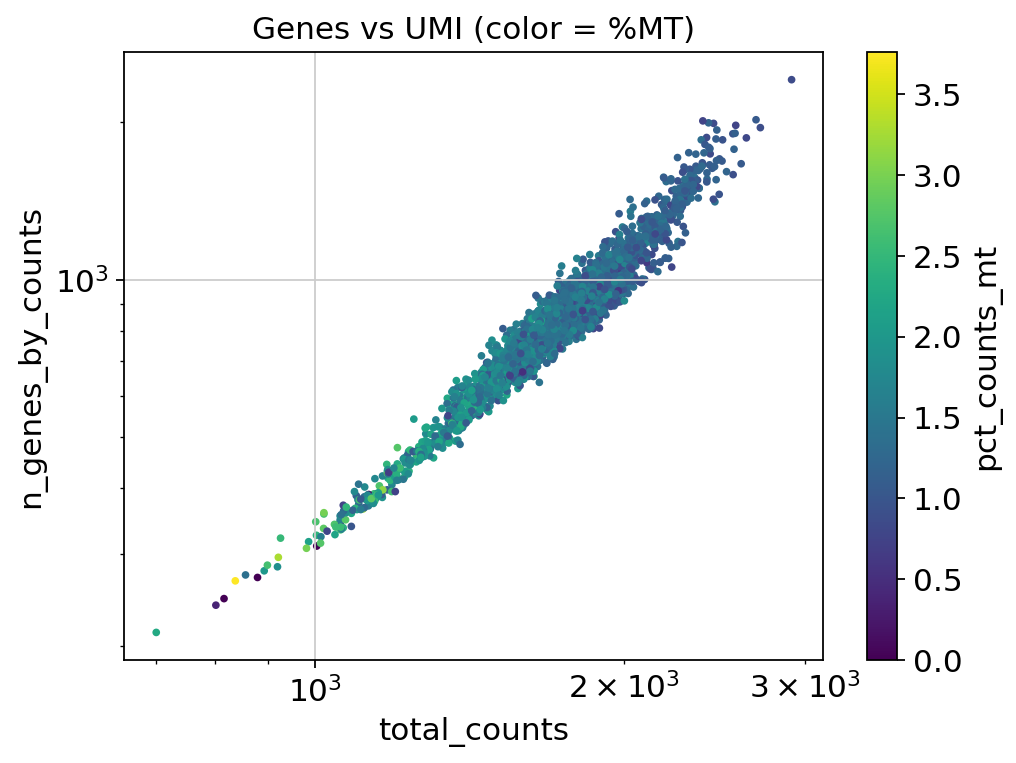

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
            c=adata.obs["pct_counts_mt"], s=6, cmap="viridis")
plt.colorbar(label="pct_counts_mt")
plt.xlabel("total_counts"); plt.ylabel("n_genes_by_counts")
plt.xscale("log"); plt.yscale("log")
plt.title("Genes vs UMI (color = %MT)")
plt.show()

**Выводы.** Подозрительны клетки с очень низким `total_counts`/`n_genes_by_counts`
(пустые/повреждённые капли) и с высоким `pct_counts_mt` (лизис мембраны).
Высокая доля рибосомных/гемоглобиновых генов не всегда = плохое качество:
эритроциты и активно секретирующие клетки действительно имеют много таких транскриптов;
контаминация гемоглобином — признак примеси эритроцитов, а не «плохой» клетки.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


In [ ]:
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
adata.var["hvg_seurat"] = adata.var["highly_variable"]

sc.experimental.pp.highly_variable_genes(adata, flavor="pearson_residuals", n_top_genes=2000)
adata.var["hvg_pearson"] = adata.var["highly_variable"]

print("HVG counts:",
      adata.var.get("hvg_v3", pd.Series(dtype=bool)).sum(),
      adata.var["hvg_seurat"].sum(),
      adata.var["hvg_pearson"].sum())

HVG counts: 0 2000 2000


In [ ]:
adata.var["hvg_v3"] = adata.var["highly_variable"]

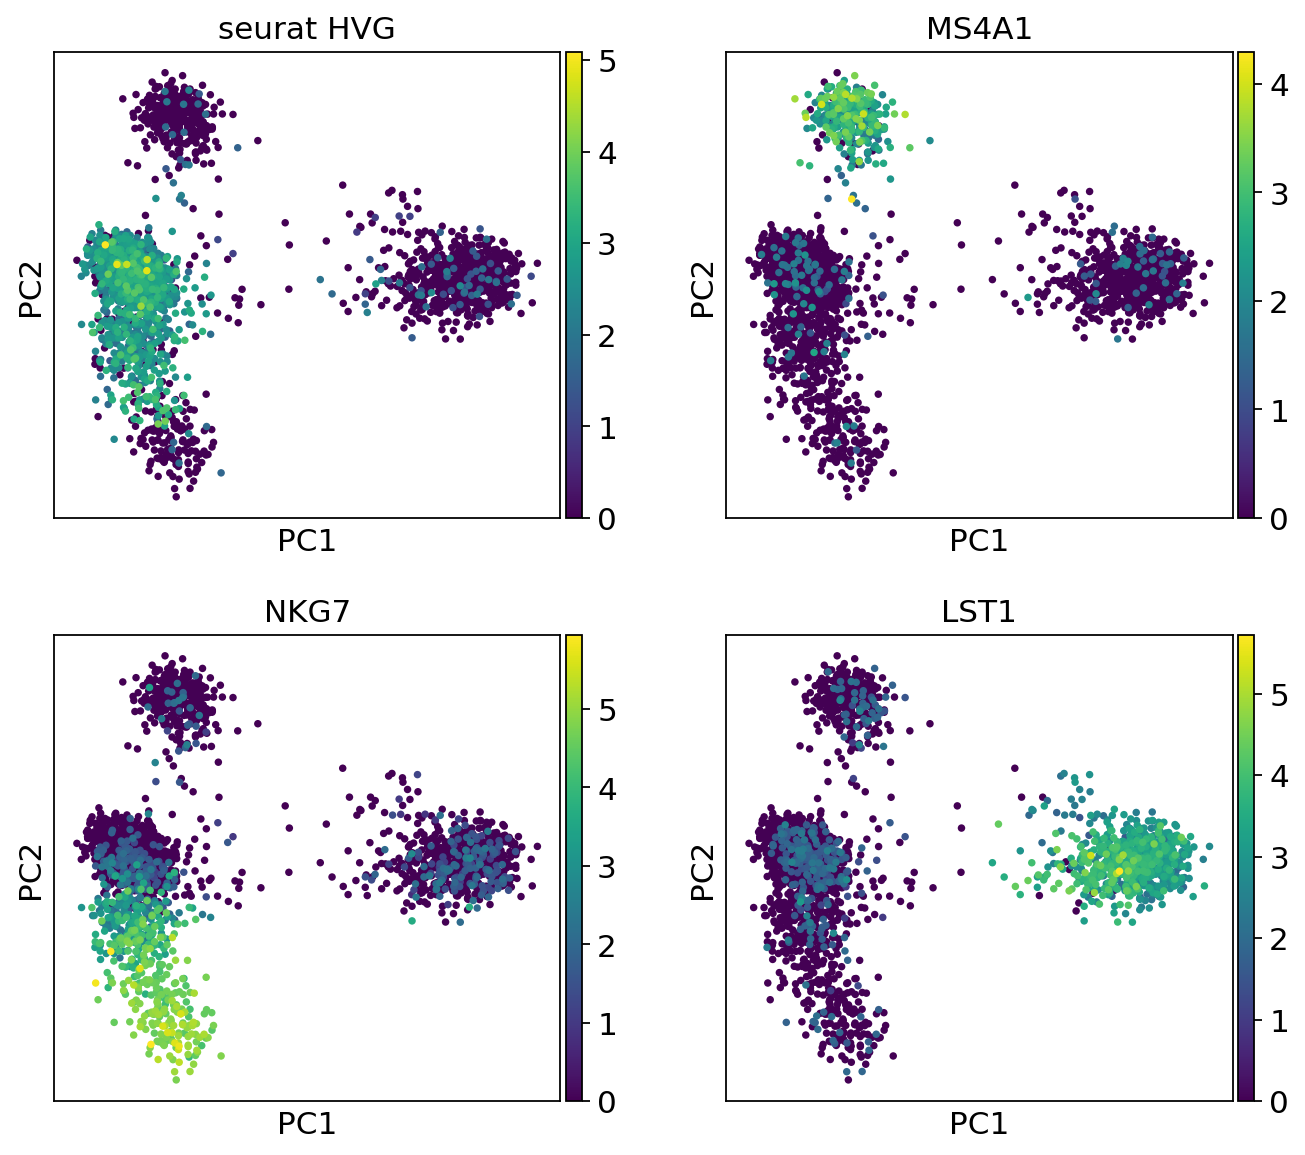

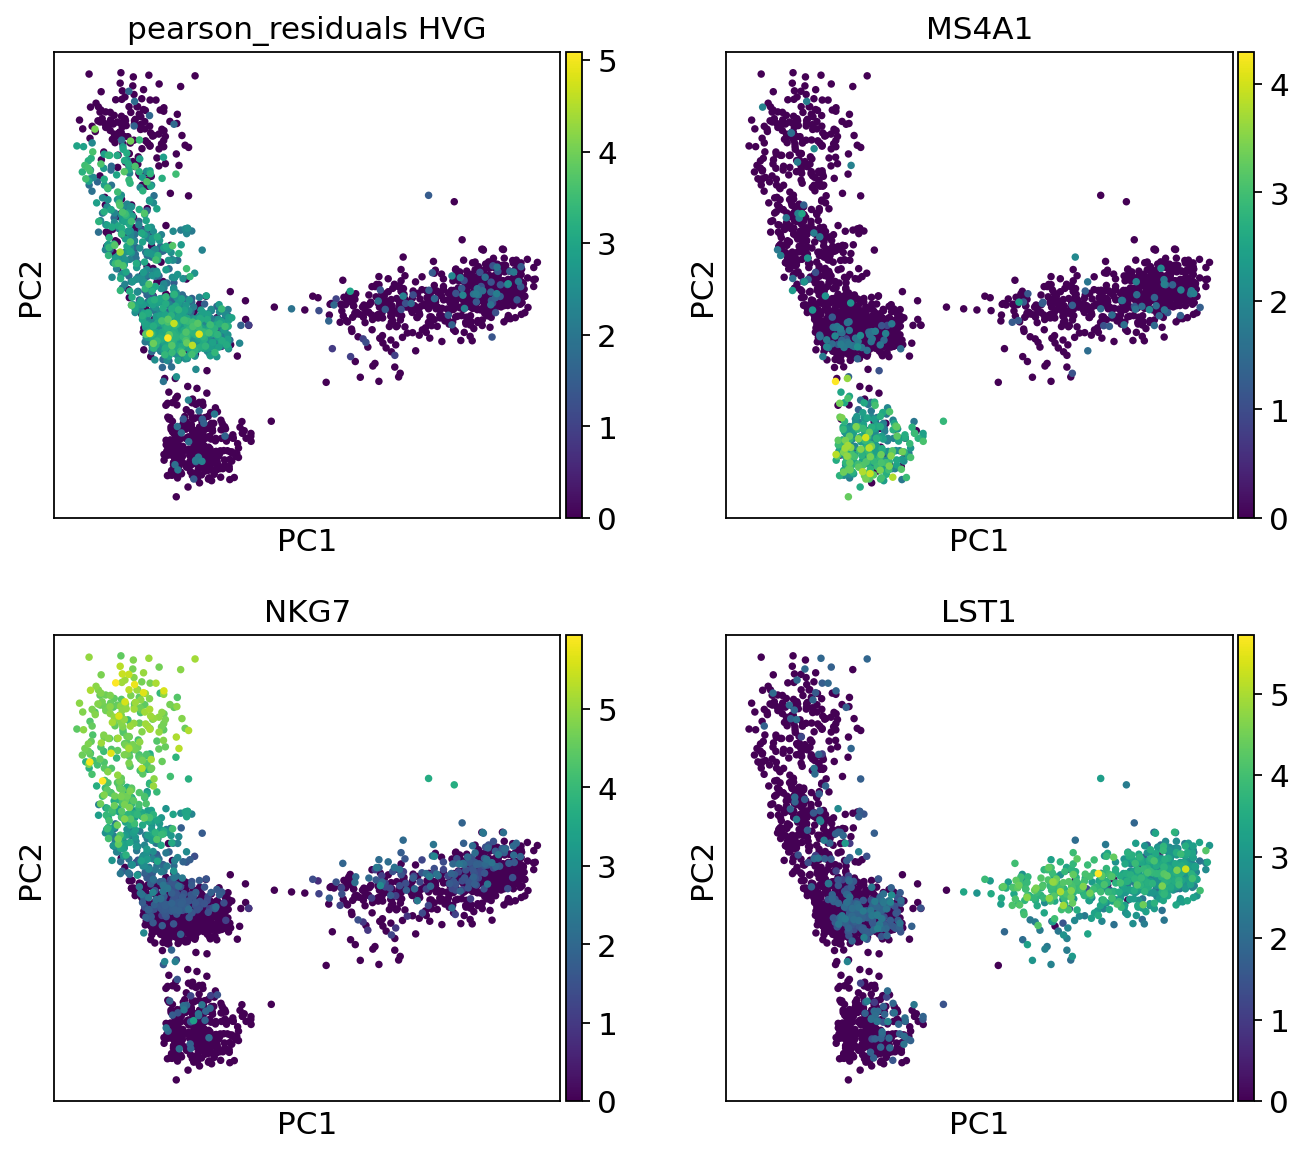

In [ ]:
def pca_with_hvg(adata_in, hvg_col, n_comps=30):
    a = adata_in.copy()
    a.var["highly_variable"] = a.var[hvg_col]
    sc.tl.pca(a, n_comps=n_comps, mask_var="highly_variable")
    return a

ad_seurat  = pca_with_hvg(adata, "hvg_seurat")
ad_pearson = pca_with_hvg(adata, "hvg_pearson")

sc.pl.pca(ad_seurat,  color=["CD3D", "MS4A1", "NKG7", "LST1"], ncols=2,
          title="seurat HVG")
sc.pl.pca(ad_pearson, color=["CD3D", "MS4A1", "NKG7", "LST1"], ncols=2,
          title="pearson_residuals HVG")

In [ ]:
sets = {
    "v3":      set(adata.var_names[adata.var["hvg_v3"]]),
    "seurat":  set(adata.var_names[adata.var["hvg_seurat"]]),
    "pearson": set(adata.var_names[adata.var["hvg_pearson"]]),
}
print("v3 ∩ seurat :", len(sets["v3"] & sets["seurat"]))
print("v3 ∩ pearson:", len(sets["v3"] & sets["pearson"]))
print("all three   :", len(sets["v3"] & sets["seurat"] & sets["pearson"]))

v3 ∩ seurat : 750
v3 ∩ pearson: 2000
all three   : 750


**Выводы.** Расположения клеток похожи, маркерные группы (T/B/NK/моноциты)
сохраняются при любом методе отбора HVG. Число общих генов обычно ~1000–1400
между v3 и seurat, меньше — с pearson_residuals; но топ-структура PCA устойчива.

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


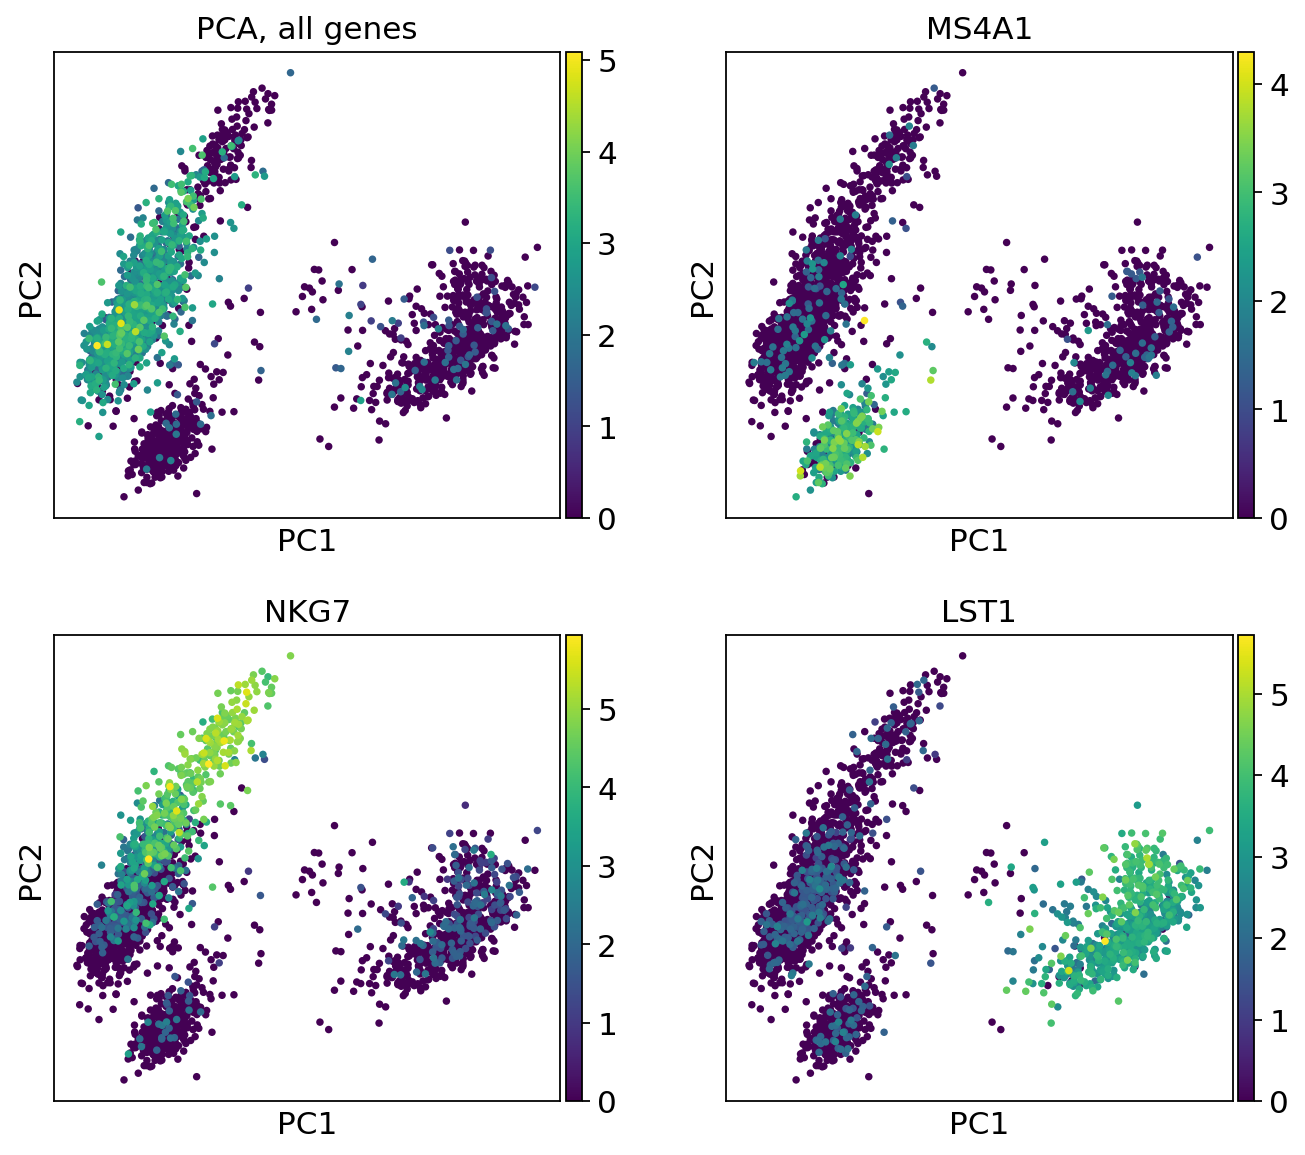

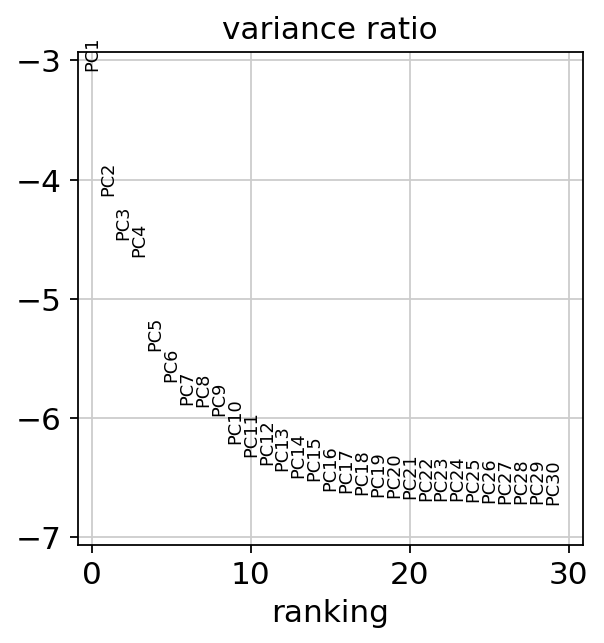

In [ ]:
ad_all = adata.copy()
ad_all.var["highly_variable"] = True
sc.tl.pca(ad_all, n_comps=30, mask_var=None)

sc.pl.pca(ad_all, color=["CD3D", "MS4A1", "NKG7", "LST1"], ncols=2,
          title="PCA, all genes")
sc.pl.pca_variance_ratio(ad_all, n_pcs=30, log=True)

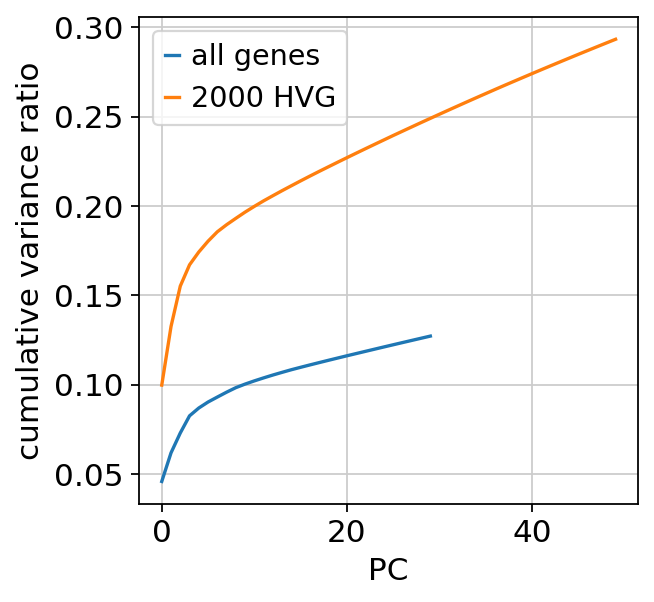

In [ ]:
plt.plot(np.cumsum(ad_all.uns["pca"]["variance_ratio"]), label="all genes")
plt.plot(np.cumsum(adata.uns["pca"]["variance_ratio"]), label="2000 HVG")
plt.xlabel("PC"); plt.ylabel("cumulative variance ratio"); plt.legend(); plt.show()

**Выводы.** Без HVG первые компоненты часто отражают технические/экстремальные гены
(MT, рибосомные, гемоглобин), структура зашумляется. Больше дисперсии в первых PC,
но биологическая интерпретируемость ниже: «информативнее» ≠ «полезнее».

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [ ]:
counts = adata.layers["counts"]
mean_counts = np.asarray(counts.mean(axis=0)).ravel()
adata.var["mean_counts"] = mean_counts

hvg_mask = adata.var["hvg_v3"].values

top_hvg = adata.var.loc[hvg_mask].nlargest(50, "mean_counts")[["mean_counts", "variances"]]
top_nonhvg = adata.var.loc[~hvg_mask].nlargest(50, "mean_counts")[["mean_counts", "variances"]]

print("Top-50 HVG по среднему UMI:\n", top_hvg.head(15))
print("\nTop-50 non-HVG по среднему UMI:\n", top_nonhvg.head(15))

Top-50 HVG по среднему UMI:
          mean_counts  variances
LYZ        10.408192   3.604221
HLA-DRA     6.151281   3.239430
S100A9      6.146330   3.317428
CST3        4.471583   2.918371
TYROBP      3.527301   2.793094
S100A8      3.174760   2.571320
NKG7        2.637610   2.433361
AIF1        2.288484   2.070428
LST1        2.205845   2.012162
CCL5        2.019716   2.271840
GNLY        1.599320   1.516955
FCN1        1.579610   1.740355
LGALS2      0.871494   1.241577
FCGR3A      0.764596   0.981765
GZMB        0.734269   1.029175

Top-50 non-HVG по среднему UMI:
         mean_counts  variances
MALAT1    60.036732   0.468708
TMSB4X    46.140289   0.201190
B2M       45.289223   0.248560
RPL10     33.017464   0.199178
RPL13     28.774101   0.315457
RPL13A    28.644434   0.270207
FTL       27.999430   1.673064
RPS2      24.092089   0.269603
RPS6      23.292944   0.364897
FTH1      21.535463   1.316607
RPS18     20.609489   0.327317
RPL11     19.285789   0.270066
RPL32     19.239534   

In [ ]:
print("mean of mean_counts in HVG :", adata.var.loc[hvg_mask, "mean_counts"].mean())
print("mean of mean_counts in non-HVG:", adata.var.loc[~hvg_mask, "mean_counts"].mean())

mean of mean_counts in HVG : 0.043505512
mean of mean_counts in non-HVG: 0.19498596


**Выводы.** HVG — не самые экспрессируемые гены. В топе non-HVG обычно MT-гены,
рибосомные (RPL/RPS), гемоглобины, MALAT1, B2M, ACTB — они высоко экспрессированы
во всех клетках, поэтому дисперсия у них низкая относительно среднего (не информативны
для разделения клеток). HVG — это гены с высокой дисперсией относительно среднего,
т.е. маркеры различий между клетками.

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

In [ ]:
def pipeline(raw, do_filter=True, do_hvg=True, n_comps=30):
    a = raw.copy()
    a.var["mt"] = a.var_names.str.startswith("MT-")
    a.var["ribo"] = a.var_names.str.startswith(("RPS", "RPL"))
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt", "ribo"],
                               percent_top=None, inplace=True)
    if do_filter:
        sc.pp.filter_cells(a, min_genes=200)
        sc.pp.filter_genes(a, min_cells=3)
        a = a[(a.obs.n_genes_by_counts < 2500) &
              (a.obs.pct_counts_mt < 5)].copy()
    a.layers["counts"] = a.X.copy()
    sc.pp.normalize_total(a, target_sum=1e4)
    sc.pp.log1p(a)
    if do_hvg:
        sc.pp.highly_variable_genes(a, layer="counts",
                                    flavor="seurat_v3", n_top_genes=2000)
        sc.tl.pca(a, n_comps=n_comps, mask_var="highly_variable")
    else:
        sc.tl.pca(a, n_comps=n_comps, mask_var=None)
    return a

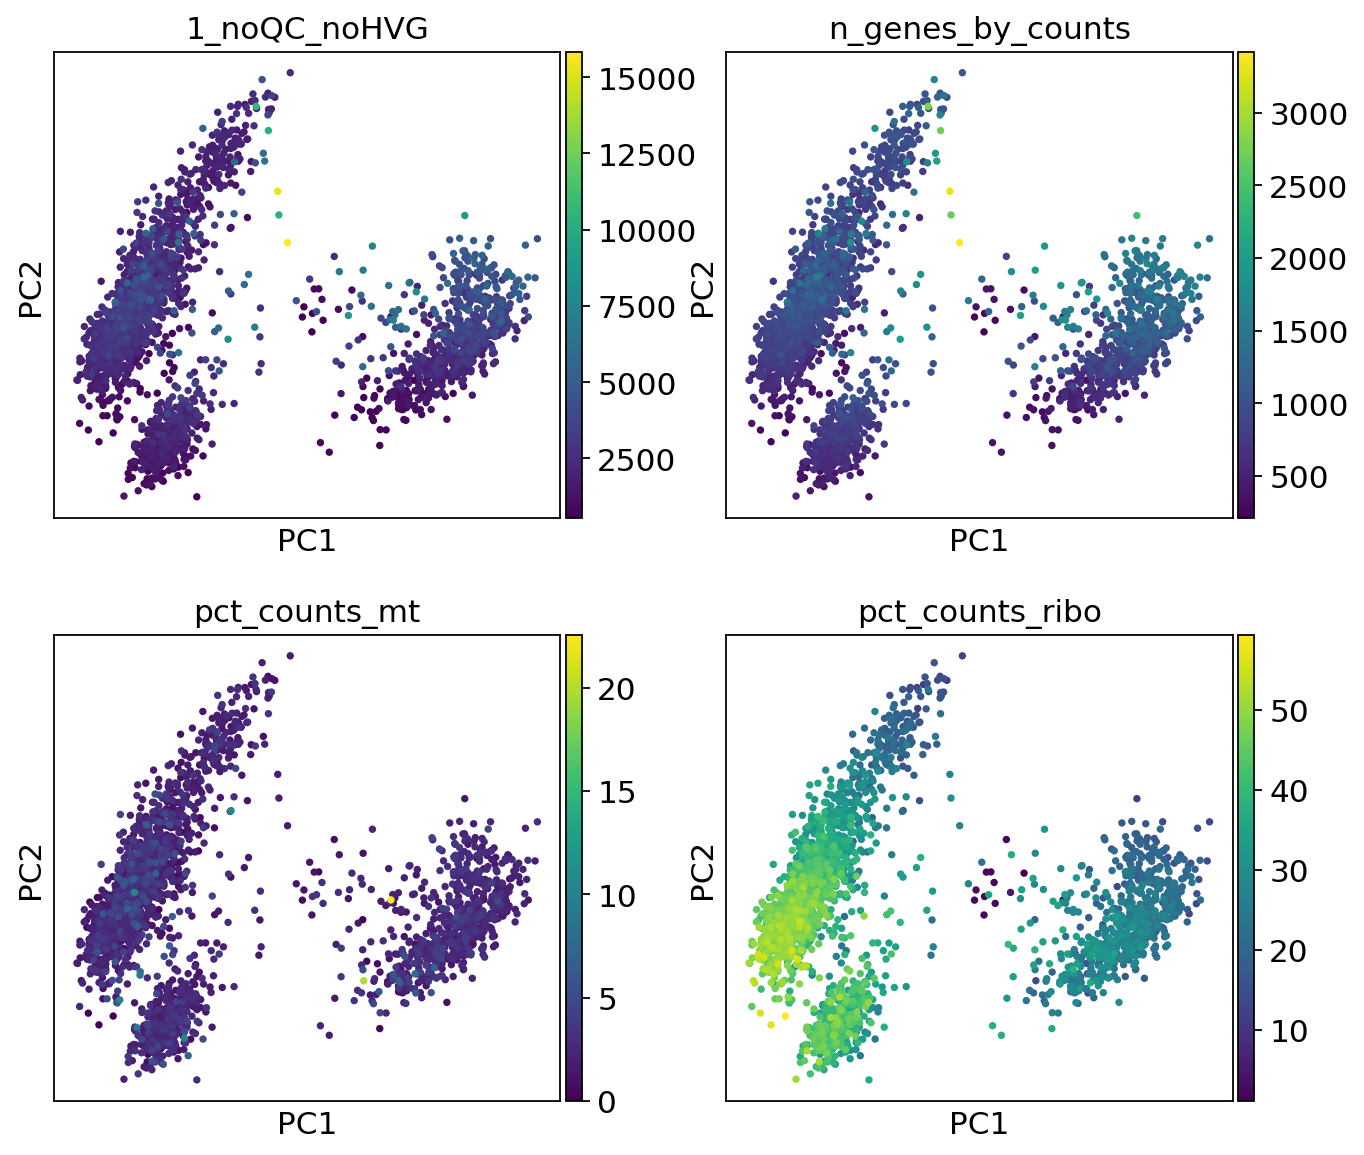

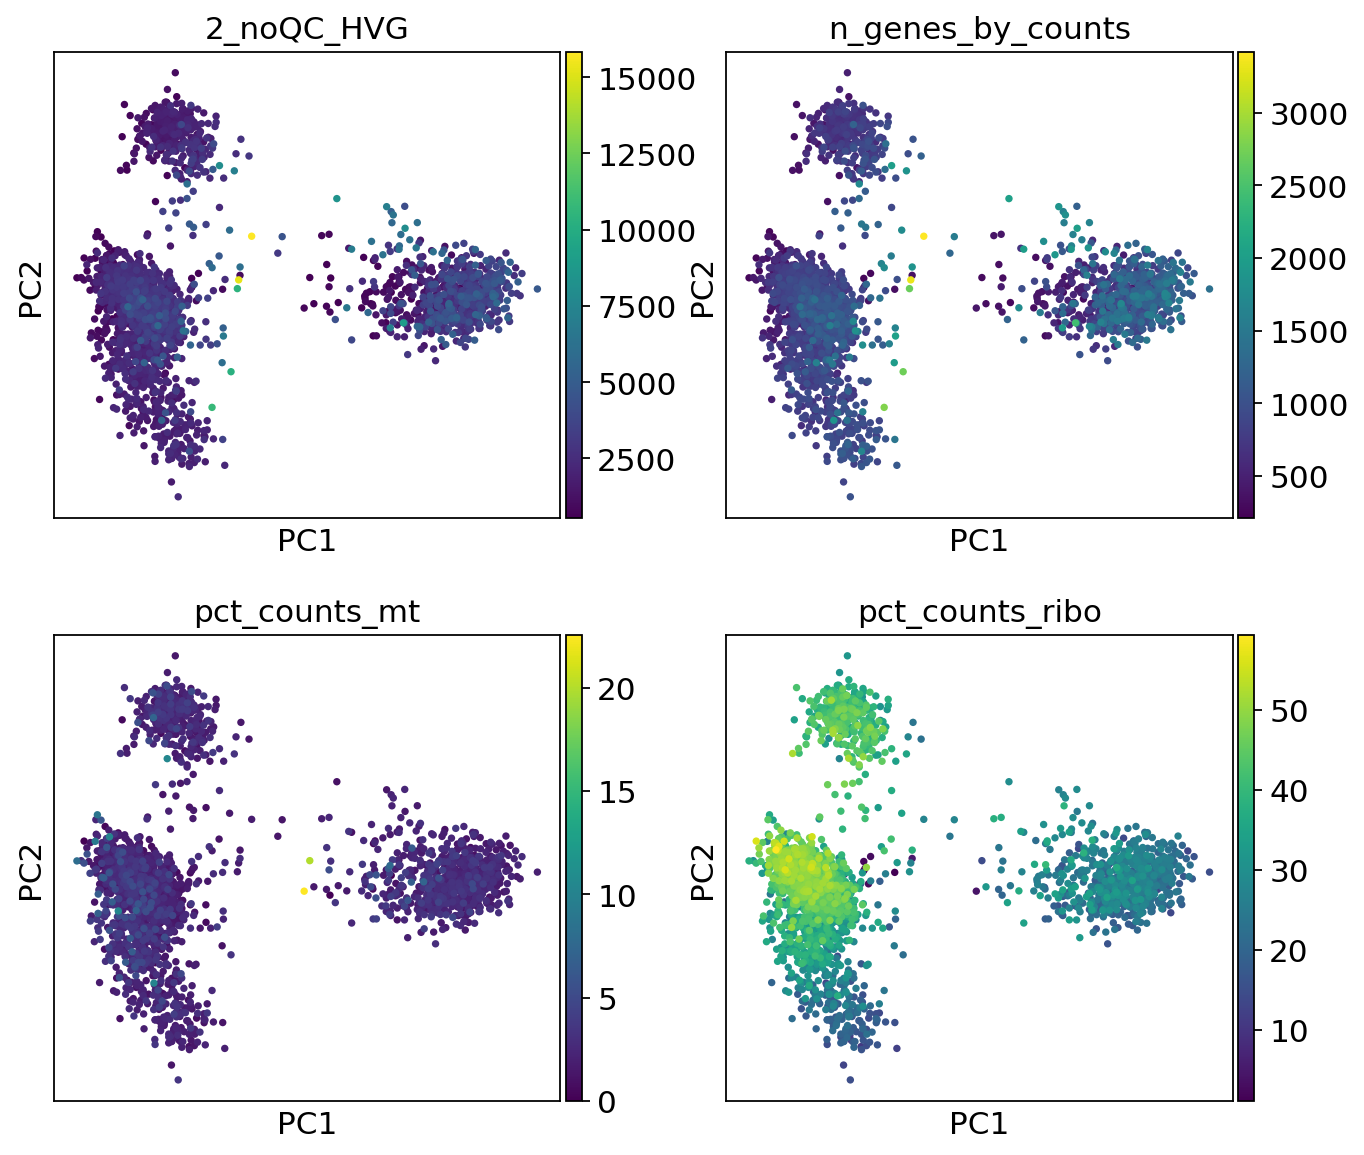

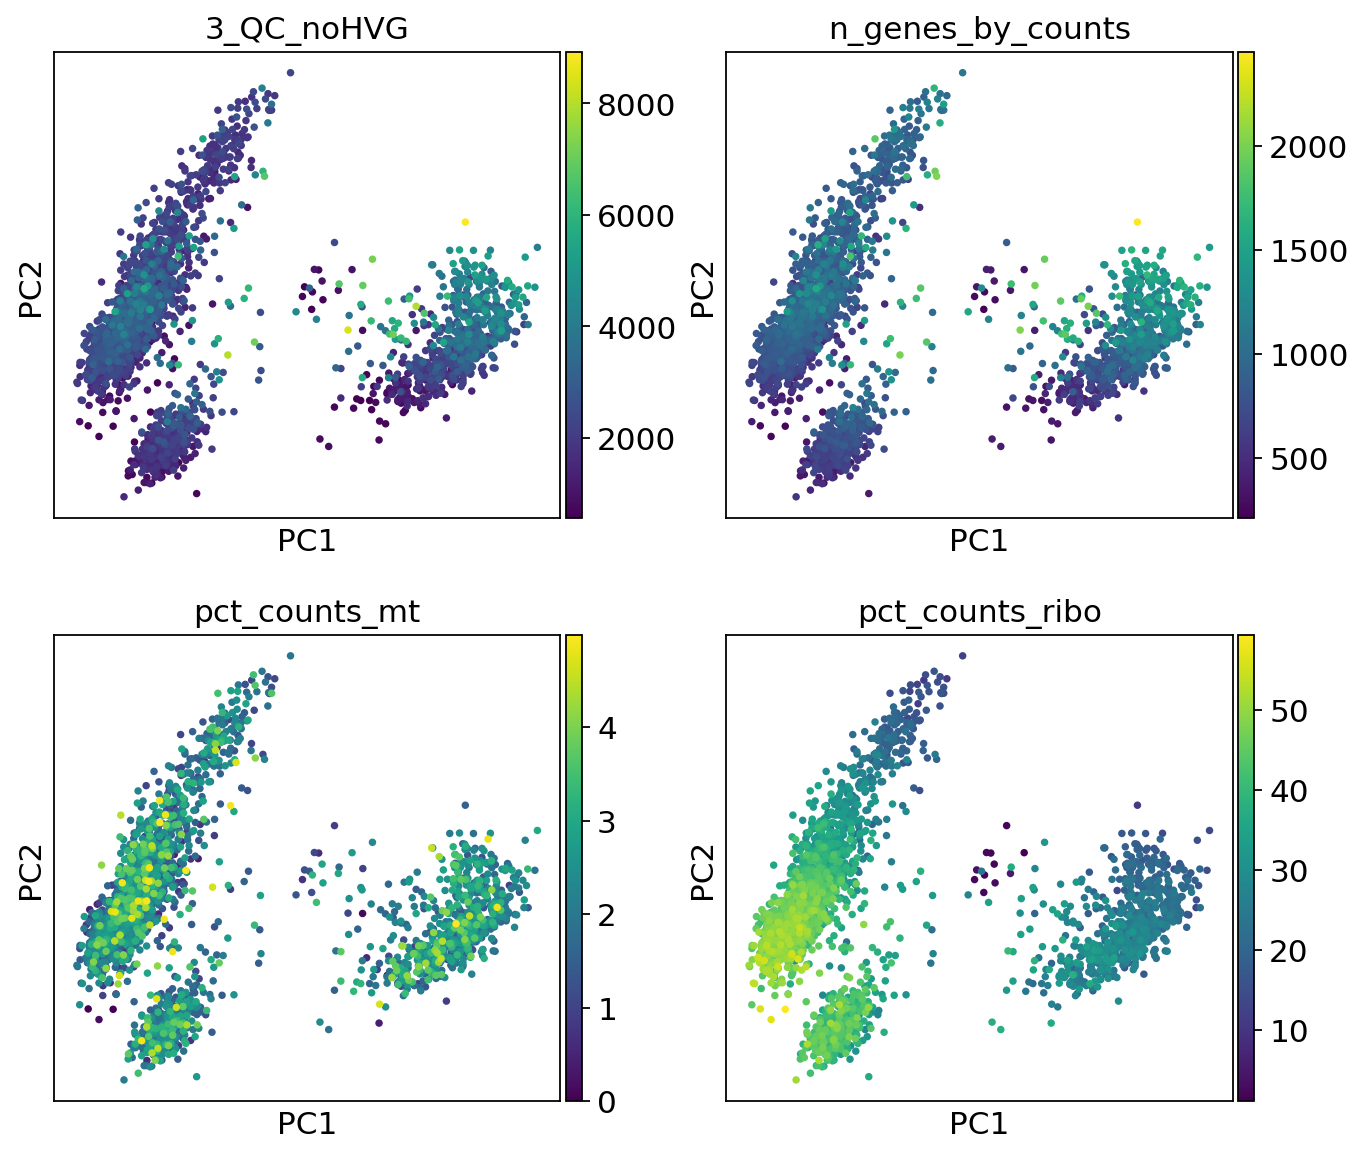

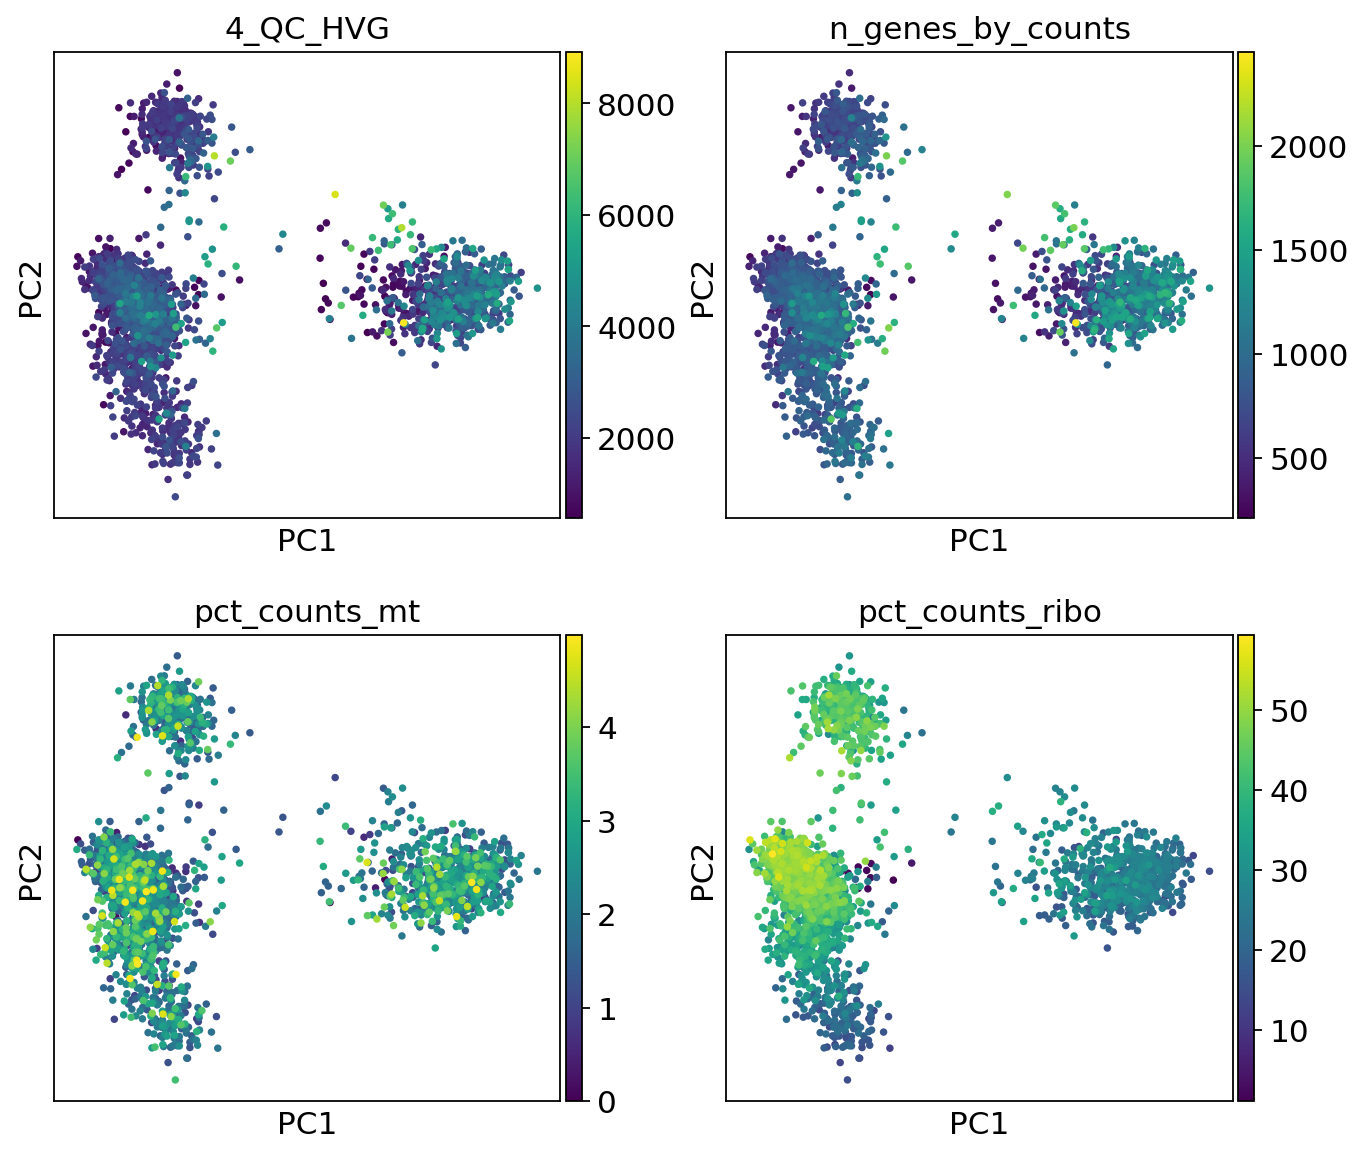

In [ ]:
raw = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
variants = {
    "1_noQC_noHVG":   pipeline(raw, do_filter=False, do_hvg=False),
    "2_noQC_HVG":     pipeline(raw, do_filter=False, do_hvg=True),
    "3_QC_noHVG":     pipeline(raw, do_filter=True,  do_hvg=False),
    "4_QC_HVG":       pipeline(raw, do_filter=True,  do_hvg=True),
}
for name, a in variants.items():
    sc.pl.pca(a, color=["total_counts", "n_genes_by_counts",
                        "pct_counts_mt", "pct_counts_ribo"],
              ncols=2, title=name, show=True)

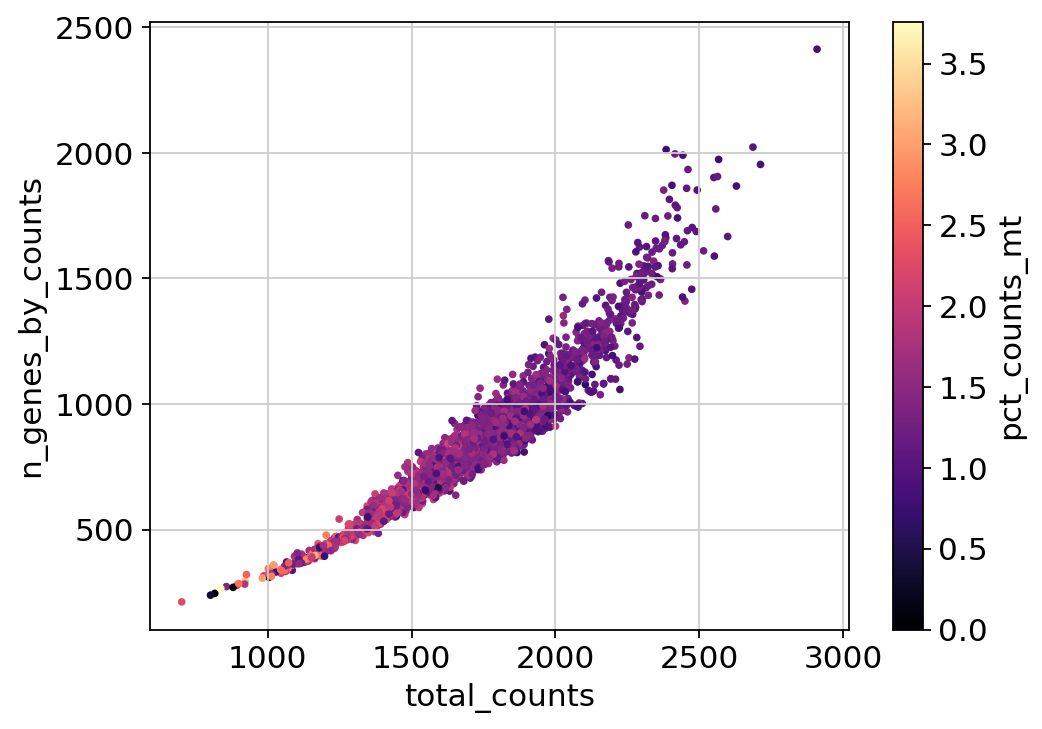

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
            c=adata.obs["pct_counts_mt"], s=6, cmap="magma")
plt.colorbar(label="pct_counts_mt")
plt.xlabel("total_counts"); plt.ylabel("n_genes_by_counts")
plt.show()

**Выводы.** Без фильтрации PC1/PC2 коррелируют с total_counts / n_genes —
технический «размер библиотеки» доминирует. Без фильтрации и без HVG
выбросы (мало UMI, много MT) растягивают облако. С фильтрацией + HVG
PC1/PC2 отражают биологию (T/B/NK/моноциты), а доля MT не образует
отдельного направления. Это и есть «технические факторы в PC».


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [ ]:
pcs = adata.varm["PCs"]
genes = adata.var_names.to_numpy()

for k in [0, 1]:
    order = np.argsort(pcs[:, k])
    top_pos = genes[order[-10:][::-1]]
    top_neg = genes[order[:10]]
    print(f"PC{k+1} top + loadings:", list(top_pos))
    print(f"PC{k+1} top - loadings:", list(top_neg))

PC1 top + loadings: ['LYZ', 'CST3', 'S100A9', 'TYROBP', 'S100A8', 'LGALS1', 'AIF1', 'LST1', 'FCER1G', 'FCN1']
PC1 top - loadings: ['LTB', 'IL32', 'MALAT1', 'IL7R', 'CCL5', 'CD2', 'CTSW', 'STK17A', 'ACAP1', 'CD247']
PC2 top + loadings: ['HLA-DRA', 'CD74', 'HLA-DPB1', 'HLA-DRB1', 'CD79A', 'HLA-DPA1', 'HLA-DQA1', 'HLA-DQB1', 'CD79B', 'HLA-DRB5']
PC2 top - loadings: ['NKG7', 'S100A4', 'CCL5', 'IL32', 'GNLY', 'CTSW', 'GZMA', 'CST7', 'SRGN', 'ANXA1']


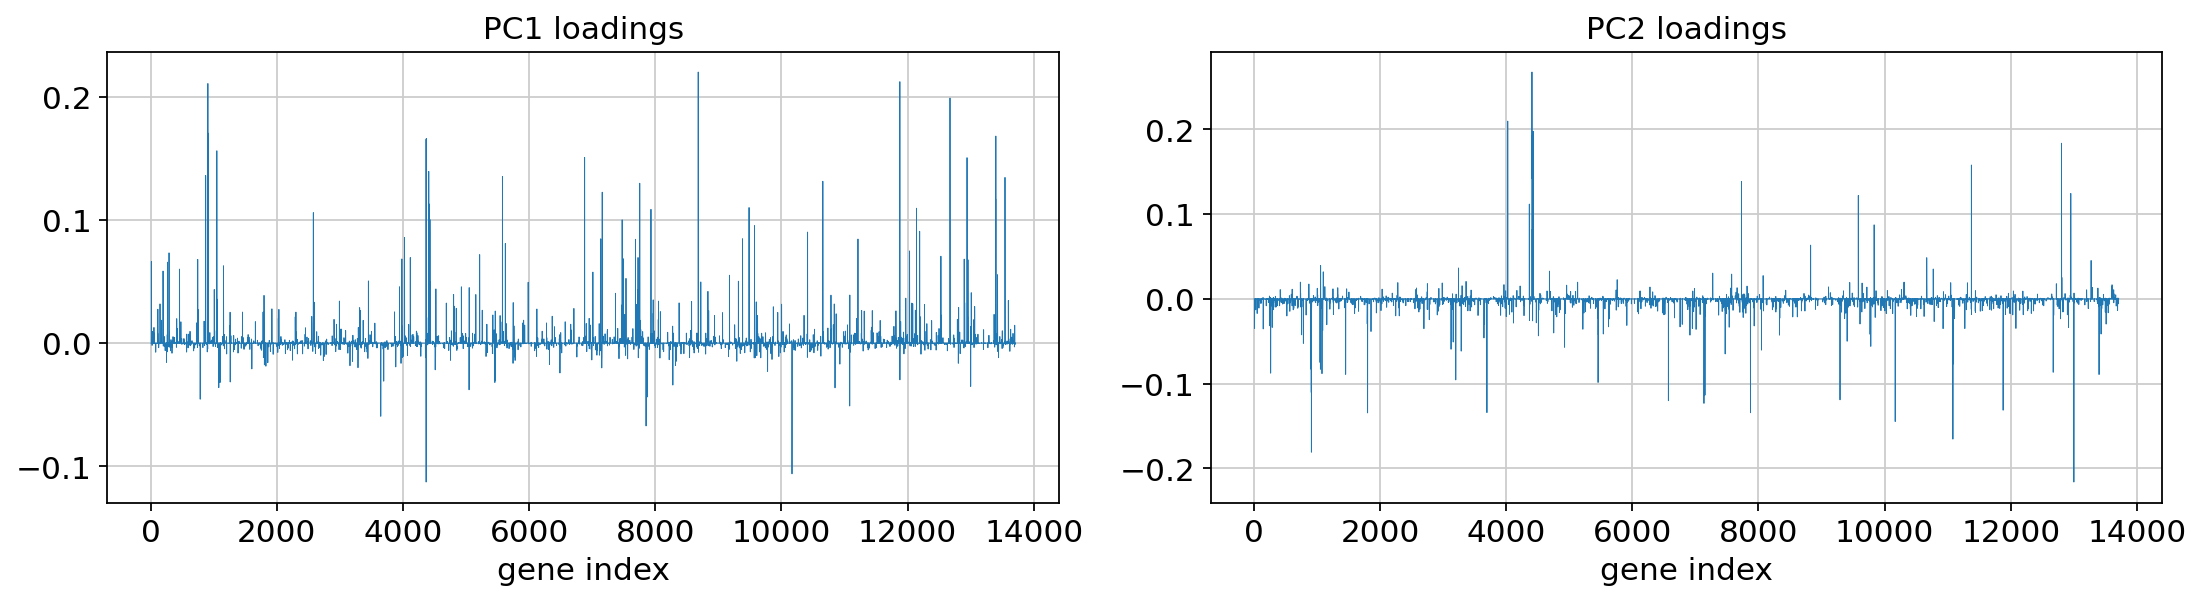

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for k, ax in enumerate(axes):
    vals = pcs[:, k]
    ax.plot(vals, lw=0.4)
    ax.set_title(f"PC{k+1} loadings"); ax.set_xlabel("gene index")
plt.tight_layout(); plt.show()

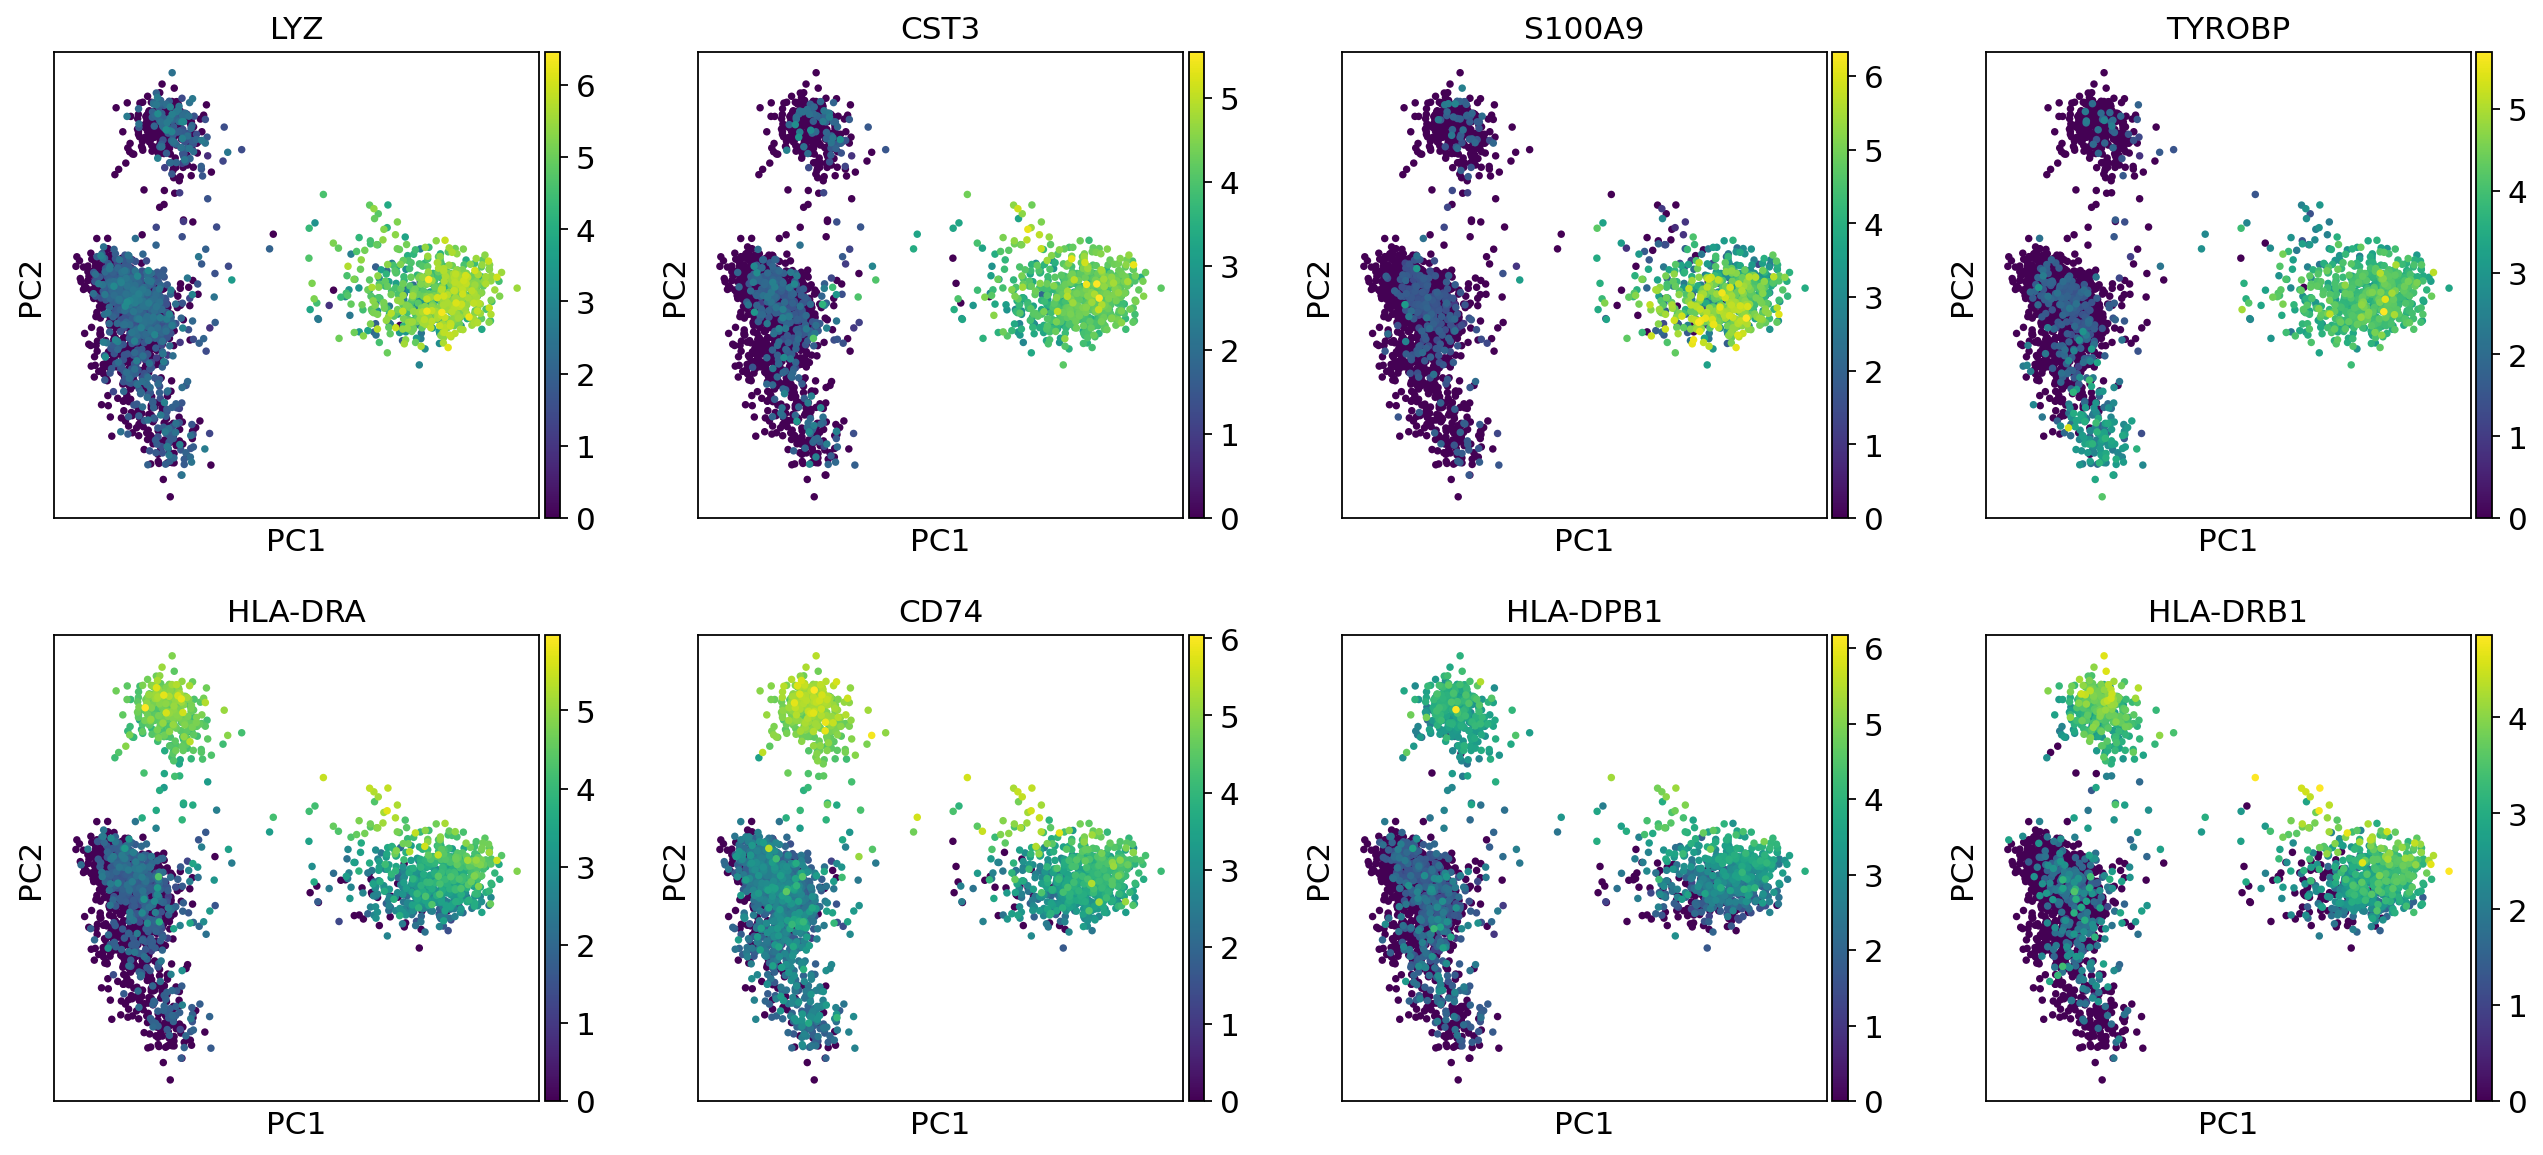

In [ ]:
top_pc1 = genes[np.argsort(pcs[:, 0])[-4:][::-1]]
top_pc2 = genes[np.argsort(pcs[:, 1])[-4:][::-1]]
sc.pl.pca(adata, color=list(top_pc1) + list(top_pc2), ncols=4)

**Выводы.** PC1/PC2 обычно определяются маркерами иммунных популяций
(CD3D/CD79A/MS4A1/NKG7/LST1/CD14/LYZ) — их можно биологически интерпретировать.
Если в топ-loadings попадают MT/RP-гены — значит QC-факторы ещё влияют на PC,
стоит усилить фильтрацию. Клеточный цикл (MKI67, TOP2A) может давать отдельную PC.

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

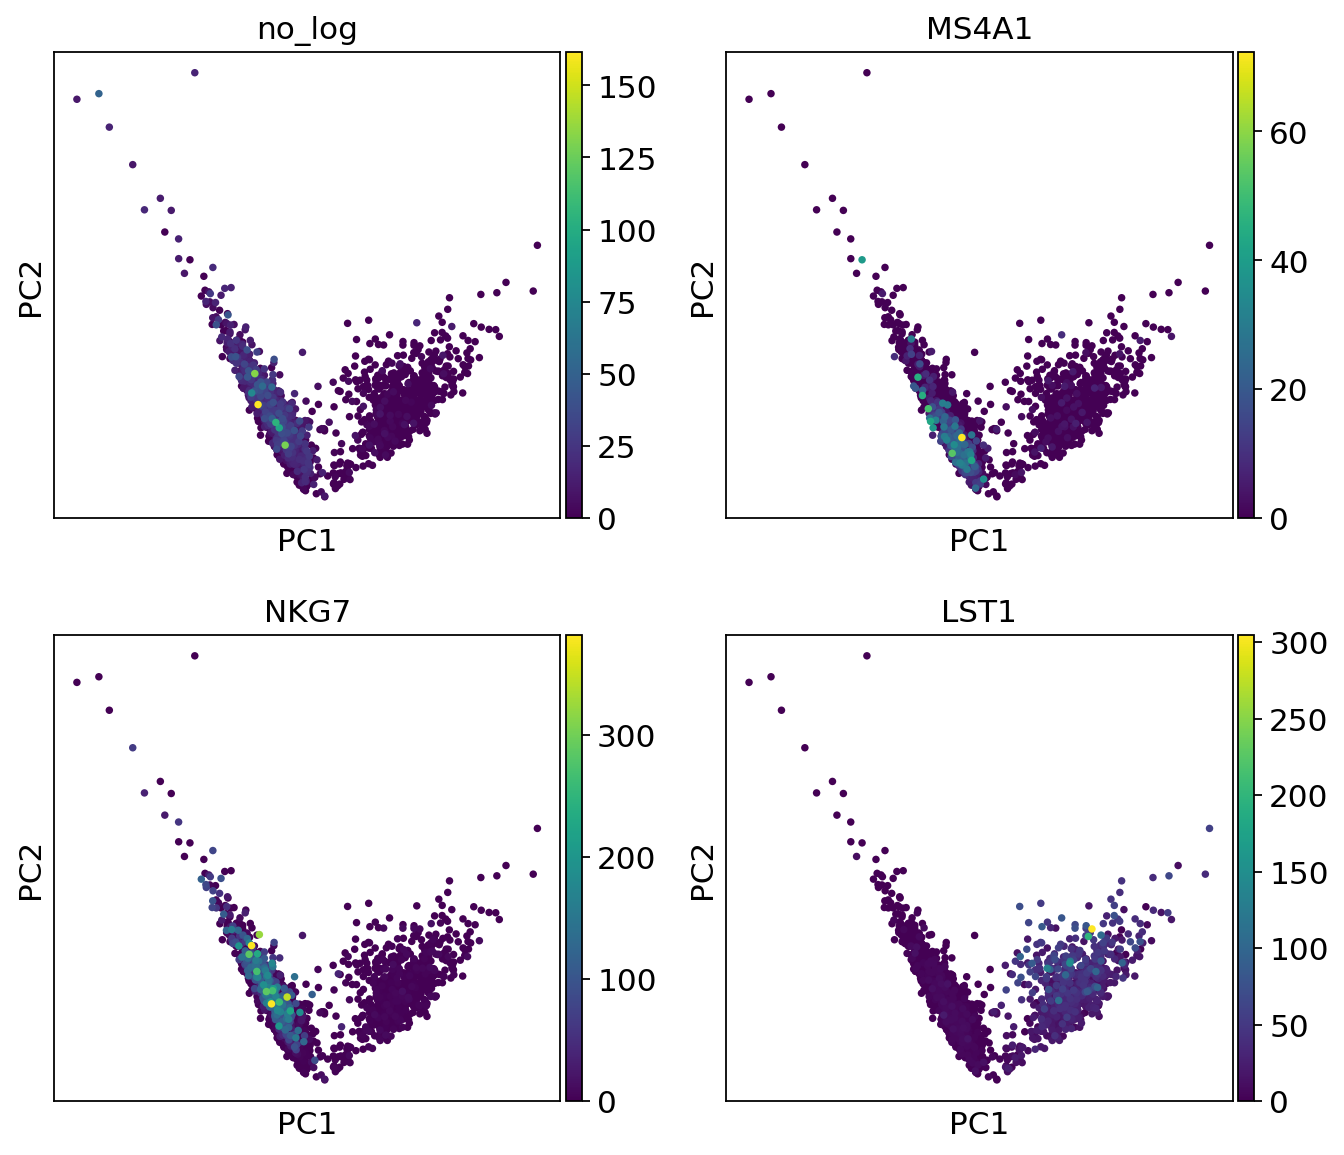

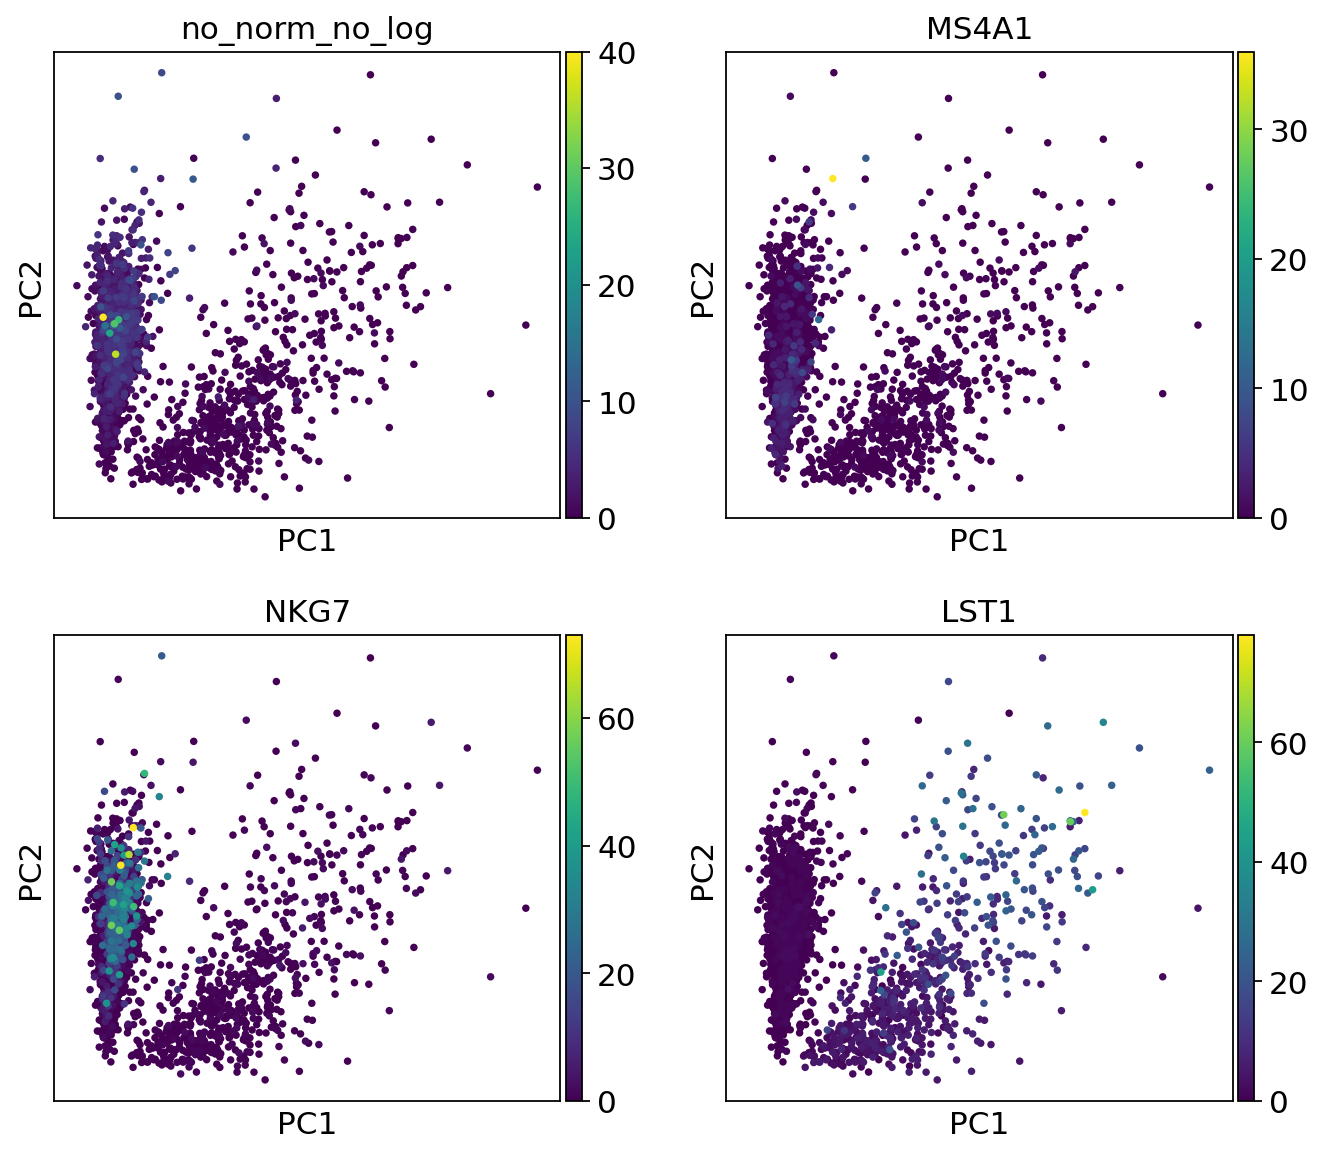

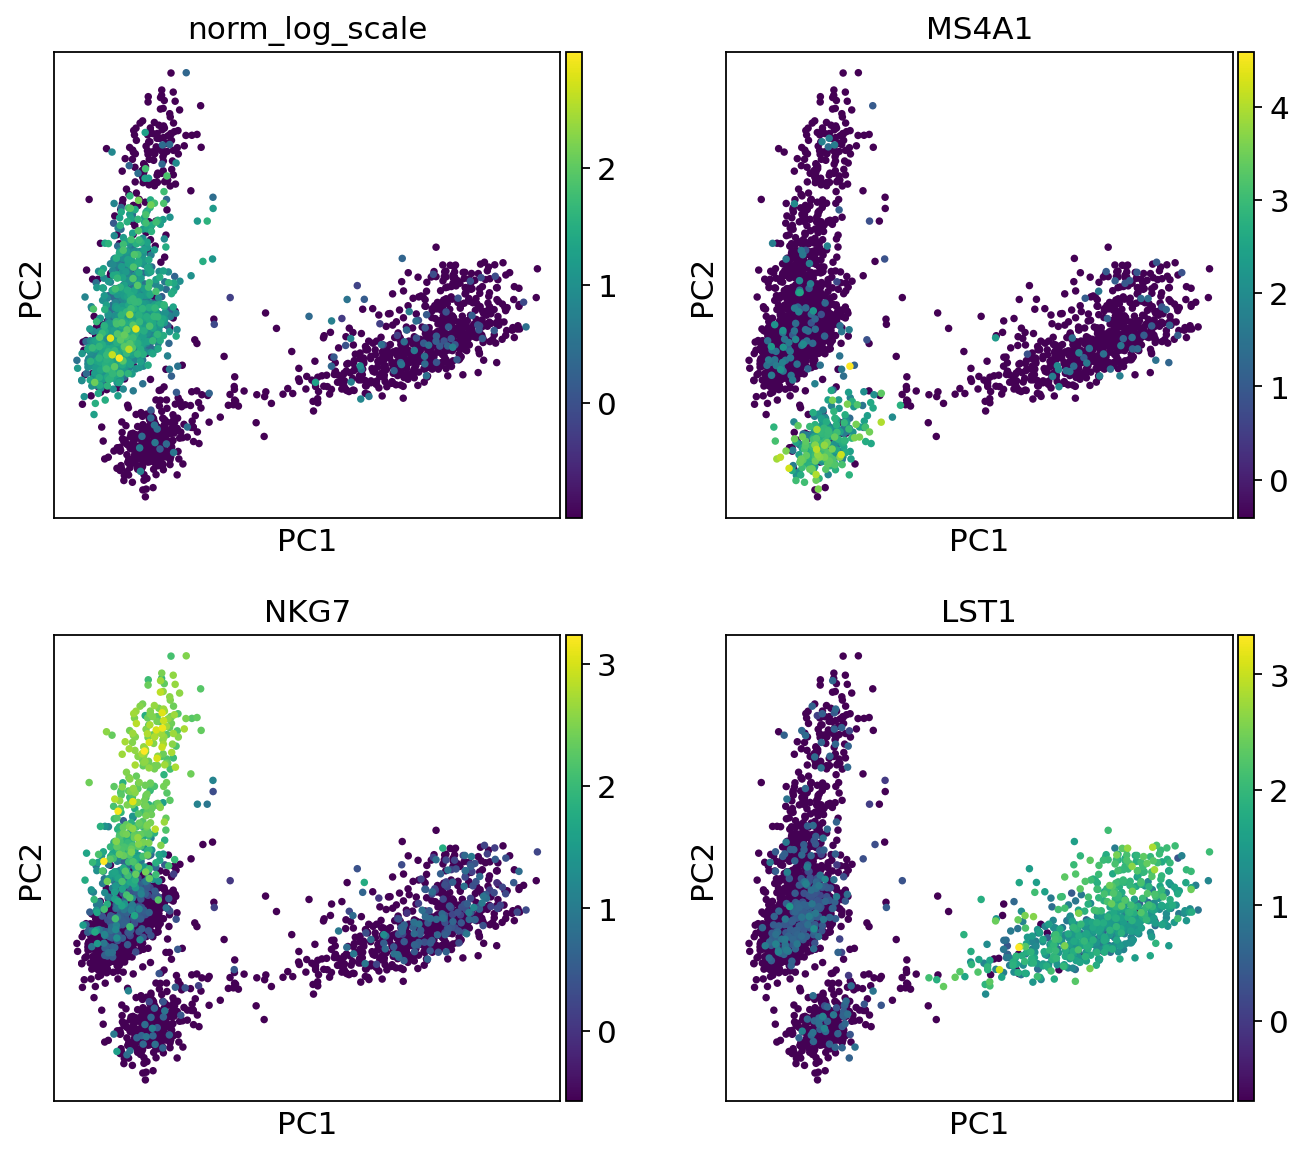

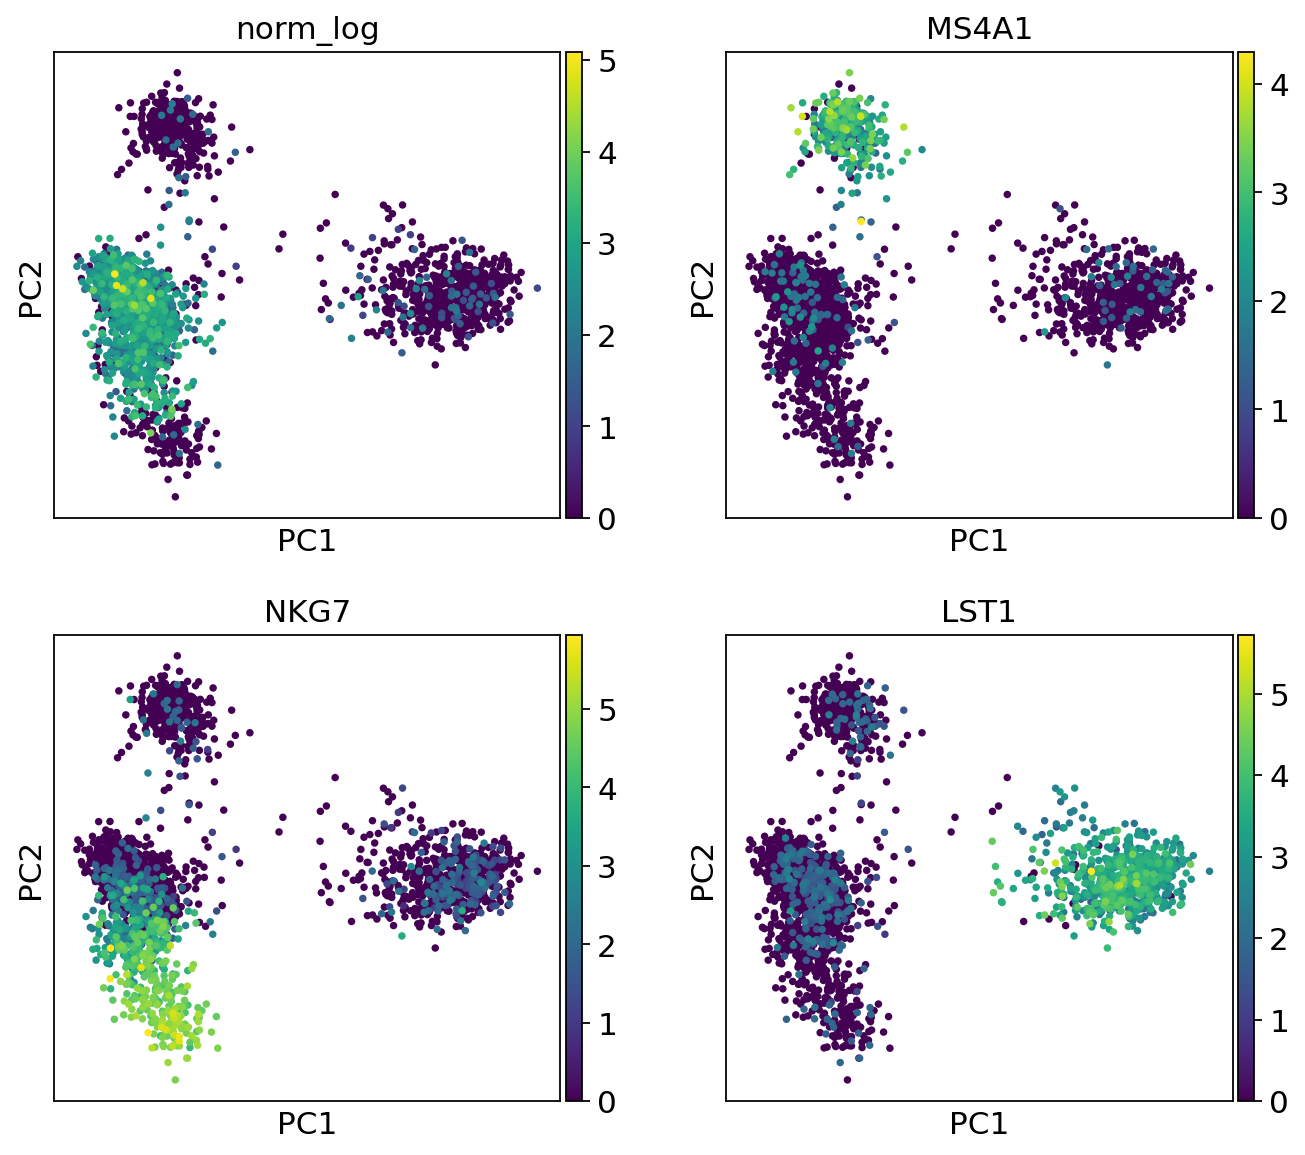

In [ ]:
def prep(raw, do_norm=True, do_log=True, do_scale=False):
    a = raw.copy()
    a.var["mt"] = a.var_names.str.startswith("MT-")
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt"], percent_top=None, inplace=True)
    sc.pp.filter_cells(a, min_genes=200)
    sc.pp.filter_genes(a, min_cells=3)
    a = a[(a.obs.n_genes_by_counts < 2500) & (a.obs.pct_counts_mt < 5)].copy()
    a.layers["counts"] = a.X.copy()
    if do_norm:
        sc.pp.normalize_total(a, target_sum=1e4)
    if do_log:
        sc.pp.log1p(a)
    if do_scale:
        sc.pp.scale(a, max_value=10)
    sc.pp.highly_variable_genes(a, layer="counts",
                                flavor="seurat_v3", n_top_genes=2000)
    sc.tl.pca(a, mask_var="highly_variable")
    return a

raw = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
cases = {
    "no_log":        prep(raw, do_norm=True,  do_log=False),
    "no_norm_no_log":prep(raw, do_norm=False, do_log=False),
    "norm_log_scale":prep(raw, do_norm=True,  do_log=True, do_scale=True),
    "norm_log":      prep(raw, do_norm=True,  do_log=True),
}
for name, a in cases.items():
    sc.pl.pca(a, color=["CD3D", "MS4A1", "NKG7", "LST1"],
              ncols=2, title=name)

**Выводы.**
- Нормализация убирает зависимость от глубины секвенирования — без неё PC1
  ≈ total_counts (технический артефакт).
- log1p стабилизирует дисперсию, «сжимает» сильно экспрессированные гены,
  делает PCA более биологичным; без лога доминируют гены-«киты».
- scale стандартизирует каждый ген к нулю/единице, усиливает вклад
  низкоэкспрессированных генов и может «раздуть» шум; на counts делать нельзя.
Перед PCA обычно нужны: нормализация + лог (или Pearson residuals); scale — опционально,
чаще для downstream-моделей (регрессия, нейросети), а не для самого PCA.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?